# Mango Fruit AI V4.2.0: one three-class experimental model

This notebook trains **one Mango Fruit model** for Bacterial Black Spot, Healthy Fruit, and Mango Scab. It uses the exact V4.1.1 historical train/validation/test photo membership. It does not change the V4.1.1 model or the app. Bacterial Canker belongs to the separate Mango Leaf experiment, subject to checking its source photos.

Run Steps 1–24 in order on a Colab GPU. Each step says what it reads, saves, and how to check it. The training recipe uses V4.1.1's ordinary flip/rotation/zoom/shear/brightness augmentation **plus** approved white-background replacement and localized light/shadow, all in a single combined training arm. Scene and lighting changes apply to training photos only. Validation and test photos keep their original pixels. One source image appears once per epoch.

After Step 24, run the separate `MangoFruit_AI_Threshold_Fitting_v4_2_0.ipynb`. Then return to the **post-threshold figures section at the end of this notebook**. That section reads saved, frozen results; it does not refit thresholds, train again, or run test/OOD inference. No model is deployed by this workflow.


## Before you start: Drive inputs and output layout

Required Drive folders from V4.1.1: `/content/drive/MyDrive/mango_dataset_v3` (all original seven-class source folders), `/content/drive/MyDrive/mangoleaf_v3/dataset_split/dataset_split` (original split), `/content/drive/MyDrive/mangoleaf_background_photos`, `/content/drive/MyDrive/mango_ood_test`, and `/content/drive/MyDrive/mango_ood_test_new_photos`. The OOD folders are used for overlap auditing here, **not** for model training or threshold fitting.

The notebook makes a new `mangoleaf_experiments/v4.2.0/training/mangofruit/<run-id>/` folder. It saves the fruit-only split, reviews, masks, training history, calibrated `.keras` model, TensorFlow.js export, and training curve there. Never overwrite or merge a partial run. Keep the printed complete run path for the Fruit threshold notebook. Final evidence can later be curated under `docs/model-training/experiment/v4.2.0/artifacts/mangofruit/` and `figures/mangofruit/`; the fitted TensorFlow.js candidate is **not** copied into `public/models/mangofruit/` by this notebook.


### Step 1: Mount Drive and freeze settings

- **Purpose:** Load libraries, class order, random seed, source folders, and the V4.1 training recipe.
- **Reads:** The five Drive input folders listed above, plus written scene-source notes in `BACKGROUND_NOTES`.
- **Saves:** Printed runtime and folder paths. No training starts here.
- **Check:** Set `BACKGROUND_NOTES` to truthful source and usage-rights notes. Check GPU/runtime versions and paths before moving on.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import csv, hashlib, json, math, os, random, shutil, subprocess, sys, uuid, zipfile
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps, ImageDraw

SEED = 42
SOURCE_CLASS_NAMES = ['anthracnose', 'bacterial_black_spot', 'bacterial_canker',
                      'healthy_fruit', 'healthy_leaf', 'mango_scab', 'sooty_mold']
CLASS_NAMES = ['bacterial_black_spot', 'healthy_fruit', 'mango_scab']  # Preserve V4.1.1 relative order.
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
CONFIDENCE_THRESHOLD = 0.70
MIN_ID_RETENTION = 0.95  # Accepted mango images; not necessarily correct diagnoses.
MODEL_VERSION = 'model-v4.2.0-mangofruit-candidate'
ARMS = ('combined',)  # One model: ordinary augmentation + scene replacement + local light.
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
PREPROCESSING = 'TensorFlow RGB decode (Pillow RGB with EXIF transpose for WebP); bilinear 224x224, no antialias; float32 0-255; model rescales internally'
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy('float32')
RUNTIME = {'python': sys.version, 'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
           'numpy': np.__version__, 'pillow': Image.__version__}
print('Runtime:', RUNTIME)

RAW_DIR = Path('/content/drive/MyDrive/mango_dataset_v3')
BASELINE_SPLIT_DIR = Path('/content/drive/MyDrive/mangoleaf_v3/dataset_split/dataset_split')
# Keep each V4.2.0 candidate in a separate Drive run folder.
EXPERIMENT_ROOT = Path('/content/drive/MyDrive/mangoleaf_experiments/v4.2.0')
OUTPUT_ROOT = EXPERIMENT_ROOT / 'training' / 'mangofruit'
BACKGROUND_DIR = Path('/content/drive/MyDrive/mangoleaf_background_photos')
OLD_OOD_DIR = Path('/content/drive/MyDrive/mango_ood_test')
NEW_OOD_DIR = Path('/content/drive/MyDrive/mango_ood_test_new_photos')
BACKGROUND_NOTES = 'All the images are came from the own cellphone photos and internet public imag'  # Fill in image sources, rights, and collection dates before the run.
BLEND_PROBABILITY = 0.30  # Among approved white-background images, per epoch.
LOCAL_LIGHT_PROBABILITY = 0.30  # Among all training images, per epoch.
LIGHT_AMPLITUDE = (18.0, 40.0)  # Pixel change, bounded below clipping at 0..255.
LIGHT_RADIUS = (0.18, 0.35)  # Gaussian radius relative to 224-pixel side.
if not BACKGROUND_NOTES.strip():
    raise ValueError('Fill BACKGROUND_NOTES with scene sources and usage rights first.')
if not 0 < BLEND_PROBABILITY < 1 or not 0 < LOCAL_LIGHT_PROBABILITY < 1:
    raise ValueError('Keep original presentations in both augmentation arms.')
PHASH_DISTANCE = 5
STAGE1_EPOCHS, STAGE1_LR = 5, 1e-3
STAGE2_EPOCHS, STAGE2_LR = 10, 1e-5
AUG_ROTATION_DEG, AUG_ZOOM, AUG_BRIGHTNESS, AUG_SHEAR = 30, 0.20, 0.20, 0.20
AUG_FLIP = 'horizontal_and_vertical'
QUANTIZE_FLOAT16 = False
EVALUATION_STATUS = 'previously_used'
EVALUATION_NOTES = 'The original v3 test/OOD report images influenced earlier development.'

# Install hashing support without changing Colab's TensorFlow or NumPy versions.
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps', 'ImageHash==4.3.2'], check=True)
import imagehash
print('Class order:', CLASS_NAMES)
print('Training output root:', OUTPUT_ROOT)
print('Training recipe:', ARMS[0])
print('Fruit class order:', CLASS_NAMES)


Mounted at /content/drive
Runtime: {'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'tensorflow': '2.20.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pillow': '11.3.0'}
Class order: ['bacterial_black_spot', 'healthy_fruit', 'mango_scab']
Training output root: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit
Training recipe: combined
Fruit class order: ['bacterial_black_spot', 'healthy_fruit', 'mango_scab']


### Step 2: Define safety and image helpers

- **Purpose:** Prepare file hashes, safe ZIP extraction, RGB decoding, probability prediction, and model-weight hashing.
- **Reads:** Python libraries loaded in 0A.
- **Saves:** Reusable functions only; no Drive files yet.
- **Check:** Understand that SHA-256 detects byte changes and `load_pixels` defines the same 224 x 224 input for training and later evaluation.


In [ ]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def object_hash(value):
    text = json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=True)
    return hashlib.sha256(text.encode()).hexdigest()


def write_json_once(path, value):
    with Path(path).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, allow_nan=False)
        handle.write('\n')


def list_images(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f'Image folder missing: {folder}')
    paths = sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if not paths:
        raise ValueError(f'No supported images in {folder}')
    return paths


def verify_records_unchanged(rows):
    for row in rows:
        if sha256_file(row['path']) != row['sha256']:
            raise RuntimeError('Image changed: ' + row['path'])


def inside(root, relative):
    relative = PurePosixPath(relative)
    if relative.is_absolute() or '..' in relative.parts or '\\' in str(relative):
        raise ValueError('Unsafe relative path: ' + str(relative))
    target = (Path(root) / str(relative)).resolve()
    if not target.is_relative_to(Path(root).resolve()) or target == Path(root).resolve():
        raise ValueError('Path must stay inside its output folder.')
    return target


def extract_dataset(archive, rows, destination):
    # Extract only recorded images, then verify their contents before inference.
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    expected = {r['relativePath']: r for r in rows}
    if len(expected) != len(rows):
        raise ValueError('The image manifest repeats a destination path.')
    with zipfile.ZipFile(archive) as bundle:
        names = bundle.namelist()
        if len(names) != len(set(names)) or set(names) != set(expected):
            raise ValueError('Dataset ZIP entries differ from the image manifest.')
        for name, row in expected.items():
            target = inside(destination, name)
            if bundle.getinfo(name).file_size != row['bytes']:
                raise ValueError('Image size changed in dataset ZIP: ' + name)
            target.parent.mkdir(parents=True, exist_ok=True)
            with bundle.open(name) as source, target.open('xb') as output:
                shutil.copyfileobj(source, output)
            if sha256_file(target) != row['sha256']:
                raise ValueError('Image contents changed in dataset ZIP: ' + name)
    return [{**r, 'path': str(inside(destination, r['relativePath']))} for r in rows]


def verify_artifacts(folder, artifacts):
    for relative, expected in artifacts.items():
        path = inside(folder, relative)
        if not path.is_file() or sha256_file(path) != expected:
            raise RuntimeError('Missing or changed saved artifact: ' + relative)


def load_pixels(path):
    # Keep V4's RGB pixels; WebP uses Pillow because tf.io.decode_image lacks it.
    if Path(path).suffix.lower() == '.webp':
        # TensorFlow's generic decoder does not support WebP. Match threshold notebook.
        with Image.open(path) as picture:
            pixels = np.asarray(ImageOps.exif_transpose(picture).convert('RGB'), dtype=np.float32)
    else:
        pixels = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        pixels.set_shape((None, None, 3))
    return tf.image.resize(pixels, IMAGE_SIZE, method='bilinear',
                           preserve_aspect_ratio=False, antialias=False)


def predict_records(model, rows):
    output = []
    for start in range(0, len(rows), BATCH_SIZE):
        batch = rows[start:start + BATCH_SIZE]
        verify_records_unchanged(batch)
        pixels = tf.stack([load_pixels(r['path']) for r in batch])
        values = model(pixels, training=False).numpy()
        if values.shape != (len(batch), len(CLASS_NAMES)) or not np.isfinite(values).all():
            raise ValueError('The model must return seven finite probabilities per image.')
        output.extend(values.tolist())
    if not output:
        raise ValueError('Cannot predict an empty image collection.')
    return np.asarray(output, dtype=np.float32)


def weight_digest(model):
    digest = hashlib.sha256()
    for variable in model.weights:
        values = variable.numpy()
        digest.update(str(values.shape).encode())
        digest.update(str(values.dtype).encode())
        digest.update(values.tobytes())
    return digest.hexdigest()


def print_class_probabilities(probabilities, title):
    # Sort label-score pairs for display; keep the model's class order unchanged.
    ranked = sorted(zip(CLASS_NAMES, map(float, probabilities), strict=True),
                    key=lambda item: item[1], reverse=True)
    print('\n' + title)
    for label, probability in ranked:
        print(f"{label.replace('_', ' ').title():<24} {probability * 100:6.2f}%")


### Step 3: Load historical image identities

- **Purpose:** Pin exact raw-source and historical-split image contents from the earlier V4/V4.1 work.
- **Reads:** The reviewed source identity list embedded in this cell.
- **Saves:** Reference SHA-256 identities in memory.
- **Check:** Do not replace these hashes to silence a mismatch. A mismatch means input collection changed and needs a separate investigation.


In [ ]:
# These identities came from the user's reviewed non-duplicate list.
# Names may change; the SHA-256 hash identifies the exact file contents.
REVIEWED_IMAGES = [{'label': 'anthracnose', 'currentName': 'verified mango leaf disease 21.jpg', 'historicalName': 'verified mango leaf disease 21.jpg', 'sha256': 'a557157b1e887d6f8f7067efbaa97447074114b2967c3c2337656d1936b45102'}, {'label': 'anthracnose', 'currentName': 'verified mango leaf disease 20.jpg', 'historicalName': 'verified mango leaf disease 20.jpg', 'sha256': '87dad59aa6422d959e3fcfffd35ddca9c918e858dd7b220f1e016ae09d741f6f'}, {'label': 'anthracnose', 'currentName': 'DSC_0119.JPG', 'historicalName': 'DSC_0119.JPG', 'sha256': '01e6fd123c9ae054d2d904fef25f543279c6c74914d44a33cd9c7488ca2861c6'}, {'label': 'anthracnose', 'currentName': 'DSC_0488.JPG', 'historicalName': 'DSC_0488.JPG', 'sha256': 'ee9676472204c9cdd0830dce3be63a9d47e646ecb9d2c70126ddcdac063e4ecd'}, {'label': 'anthracnose', 'currentName': 'DSC_0970.JPG', 'historicalName': 'DSC_0970.JPG', 'sha256': '8b5d0b0e2500ff762a773b326c6a0a3ab545e51e682a253d3776be738d61123c'}, {'label': 'anthracnose', 'currentName': 'Anthracnose on young leaves.jpeg', 'historicalName': 'Anthracnose on young leaves.jpeg', 'sha256': '5c10b4851fd67db6b5a21677e725d124491633afea45186fbe2e2a6f9bd554ec'}, {'label': 'anthracnose', 'currentName': 'AnthracnoseonMangoLeaf.jpeg', 'historicalName': 'AnthracnoseonMangoLeaf.jpeg', 'sha256': '52a0fa64a504139aa65e6cbf807ecae21be6f4933bc4c1d5e2d8797a54de7227'}, {'label': 'sooty_mold', 'currentName': 'IMG_20260219_135000.jpg', 'historicalName': 'IMG_20260219_135000.jpg', 'sha256': '2a22ee7f89ea03ad9ee924b5815ae71576d6ccd3305576dccc6f3bf00e31fce3'}, {'label': 'sooty_mold', 'currentName': 'viber_image_2024-11-15_13-17-51-567.jpg', 'historicalName': 'viber_image_2024-11-15_13-17-51-567.jpg', 'sha256': 'd785e72ca8291a194d5f56f2c75d2087ca3fd9728549246b888a3b964ce5b3c9'}, {'label': 'sooty_mold', 'currentName': 'IMG_20260219_134935.jpg', 'historicalName': 'IMG_20260219_134935.jpg', 'sha256': '6c1c6c90f2dbfdb3ab1d451b90a9ce2769222aaa237bb820bf55f782e63498d5'}, {'label': 'sooty_mold', 'currentName': 'DSC_1029.JPG', 'historicalName': 'DSC_1029.JPG', 'sha256': '7dfd201d72ea78a4557fdc5c5bddb594af538ff0270e020e73c9f382b3fa6f74'}, {'label': 'sooty_mold', 'currentName': '724869371_27534362222843583_7670640125862653147_n.jpg', 'historicalName': '724869371_27534362222843583_7670640125862653147_n.jpg', 'sha256': '81c5a02299de1f2d66627a0f709a4f0c3235066749f7f8b203840b86f8a93b3c'}, {'label': 'sooty_mold', 'currentName': '45a36510-0844-4baa-9795-3de7e0236896.jpg', 'historicalName': '45a36510-0844-4baa-9795-3de7e0236896.jpg', 'sha256': '32d90fe257d7ef563ef8166768b638a92a95c8196d33de90ced349c22b62a410'}, {'label': 'healthy_leaf', 'currentName': 'HealthyLeaf_2.jpg', 'historicalName': 'HealthyLeaf_2.jpg', 'sha256': 'e2e68e23f0fd8f88b999c0740cb577e126e78de61fa1fe71772d908ea2fc6375'}, {'label': 'healthy_leaf', 'currentName': 'HealthyLeaf_1.jpg', 'historicalName': 'HealthyLeaf_1.jpg', 'sha256': '90a7907f7a259e404f6bb8c6558bb1081f2d2942249ebb5cac4b747a2f989e0c'}, {'label': 'mango_scab', 'currentName': '15289a55-e368-4f61-a25c-85b2468243fd.jpg', 'historicalName': '15289a55-e368-4f61-a25c-85b2468243fd.jpg', 'sha256': '5a10c88561c498889b7668319c36fa1a432b942c21832e65d8c4a3063dbcf78b'}, {'label': 'mango_scab', 'currentName': 'DSC_0281.JPG', 'historicalName': 'DSC_0281.JPG', 'sha256': 'da1e429fc670c52fd75ba8cfe37b019606841ee7e012182f5696895e1ba13132'}, {'label': 'mango_scab', 'currentName': 'DSC_0966.JPG', 'historicalName': 'DSC_0966.JPG', 'sha256': 'de8cd5a96aefcccbd838a67411d44f13dcf9bf647200e40c71b7da28f26a1724'}, {'label': 'mango_scab', 'currentName': 'Scab.JPG', 'historicalName': 'Scab.JPG', 'sha256': '10344e2e95ceeafab7d77e3e28e4ebbdebd699ec7e862c9c011516038e821068'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 70.jpg', 'historicalName': 'non verified mango disease 70.jpg', 'sha256': '47a8192ddf400d3ba6397ba7d3acb21142d75267b80abe3911ba0d76e85ce995'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 71.jpg', 'historicalName': 'non verified mango disease 71.jpg', 'sha256': '0c46b7f3c43190fb6e5663d6248f81e1eca31287ea8ab8cf3c2c9113aa46a848'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 73.jpg', 'historicalName': 'non verified mango disease 73.jpg', 'sha256': '7562eee067e4a968c8f7c1f3281125bcb3546dcab2795f196ee11286e836ac09'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 68.jpg', 'historicalName': 'non verified mango disease 68.jpg', 'sha256': '281064014381e3f9d4cd163b62ec6e643364ee5a3a0840875f9c310912a30c8d'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 67.jpg', 'historicalName': 'non verified mango disease 67.jpg', 'sha256': '6e99067feab48b78d0e0c4260e342c1b64673dab00a5c18099310bb9053f1dd7'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 66.jpg', 'historicalName': 'non verified mango disease 66.jpg', 'sha256': '0e515243d9cec0d0e1f970d4ba79081606c2280ee02176e30fa24b2817784cda'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 65.jpg', 'historicalName': 'non verified mango disease 65.jpg', 'sha256': 'ae4bfcc5cd3eba0f652aa4355d1780ef6efe27af71f3d020a15b1eee2c0f975b'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 56.jpg', 'historicalName': 'non verified mango disease 56.jpg', 'sha256': 'ad4415243dc86b38c7ac7f529fdb2e09f7fc9410ded477a553a0f33ef02736fa'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 53.jpg', 'historicalName': 'non verified mango disease 53.jpg', 'sha256': '89652a16e8c0590a4fd51b9ff66c7ff9fb95a7ded8aece63c85565dad39f5fff'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 52.jpg', 'historicalName': 'non verified mango disease 52.jpg', 'sha256': 'cfb52caae3133082bc5f70c82f4b4c73589a65087409383e87453d405648391e'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 51.jpg', 'historicalName': 'non verified mango disease 51.jpg', 'sha256': 'e2c7e67b3026efe9eac0941272a41654f54c8317a2d11d7ba0eb81699891a2bd'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 49.jpg', 'historicalName': 'non verified mango disease 49.jpg', 'sha256': '7b87cb61eb26ffffde585b8cbb254795f0da834ce1c306bae76fe2b6cdf0f736'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 11.jpg', 'historicalName': 'non verified mango disease 11.jpg', 'sha256': '81a2f9abde6762ed891db43c570a5339d465682e3817c4f79917f8f497ed77cd'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 10.jpg', 'historicalName': 'verified mango disease 10.jpg', 'sha256': 'afcb278a84a3abf145a2d396bbcfa99b5818b217764c3fef07246d6993421095'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 9.jpg', 'historicalName': 'verified mango disease 9.jpg', 'sha256': '6fdc1ff1319c85198ae2d42978e9c3ec11ee82b754e982915a3df896e922e187'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 1.jpg', 'historicalName': 'verified mango disease 1.jpg', 'sha256': '156d089cee4c22e7256a0aa6ef48c84025507fcafda3b463fe39f9d9f852cd87'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 58.jpg', 'historicalName': 'verified mango disease 58.jpg', 'sha256': '7fe031c22293d0c980ddf2744d2b3732bcbe22c659281c67ef7f24ce577619c6'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 36.jpg', 'historicalName': 'verified mango disease 36.jpg', 'sha256': '22deb301d133db0af636c788508379203b6b90e4ca3ce9aa3ce238069cccfc4e'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 32.jpg', 'historicalName': 'verified mango disease 32.jpg', 'sha256': 'bbfbb925ba9bc8cb2595d501ab8180bc7378dfb199a1110793743e79a40e376f'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 6.jpg', 'historicalName': 'verified mango disease 6.jpg', 'sha256': '262ea4d6d82594a4333470180b3de1a77560fafc3acc1e0a75144260e1928e15'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 2.jpg', 'historicalName': 'verified mango disease 2.jpg', 'sha256': '1da80fe4b68725c7c39d78af8e4a42c65316c4e29d2be3756bef74c02a51d1d0'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 63.jpg', 'historicalName': 'verified mango disease 63.jpg', 'sha256': '95e7184c9c0c2c0f5e729d16513410470c77e07bc4a787d50c06f79a55977cd8'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 57.jpg', 'historicalName': 'verified mango disease 57.jpg', 'sha256': '9c9bc581355a1a4bfcd0befe2051135b7903d219df9320587cd88a28c94db5f6'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 7.jpg', 'historicalName': 'verified mango disease 7.jpg', 'sha256': '0a7326dd87f77caad7cae79d709bd7cdfcb5a0aec2ef96463782b2920b5cb55c'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 55.jpg', 'historicalName': 'verified mango disease 55.jpg', 'sha256': 'd70902b669201181ee27847a13e4bbf684a371c18957b2cbb20b6cfcbf75275a'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 45.jpg', 'historicalName': 'verified mango disease 45.jpg', 'sha256': '0827d4061caffa787cb8fab501fb3f25f6e4ef40f434ee03787136b0c8f2d4b7'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 54.jpg', 'historicalName': 'verified mango disease 54.jpg', 'sha256': '4eee0b91cfa3f2c5b66a0f334d2d2e487fd666d7aa10b3ea9f8bdfc9d36dbfea'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 8.jpg', 'historicalName': 'verified mango disease 8.jpg', 'sha256': '00239798d21836b06afea3d213aff445d509eabab9cfa5515e687afc20447e97'}, {'label': 'mango_scab', 'currentName': 'DSC_1014.JPG', 'historicalName': 'DSC_1014.JPG', 'sha256': '348841118bd2fed6966a5837ddd7dcde55cb053057371a39ce4f051aa5627bdf'}, {'label': 'mango_scab', 'currentName': 'Scab1.JPG', 'historicalName': 'Scab1.JPG', 'sha256': 'dbf4ee9f20018da3f04c542d9b369403bb8fbf0149b36c14a4363782d68d174e'}, {'label': 'mango_scab', 'currentName': '725146731_2449764938863852_7559841505625140608_n.jpg', 'historicalName': '725146731_2449764938863852_7559841505625140608_n.jpg', 'sha256': 'a86e5a775f479a63fe2528305bc350300435f8b048494a06ae13e1fd78d0d0f5'}, {'label': 'healthy_fruit', 'currentName': 'DSC_1021.JPG', 'historicalName': 'DSC_1021.JPG', 'sha256': '9872562f0d3dfe137e0db5edfbaeaa602aef7444aacded8d18ce9de1bfbf5390'}, {'label': 'healthy_fruit', 'currentName': 'DSC_1019.JPG', 'historicalName': 'DSC_1019.JPG', 'sha256': 'f744b6410bd2ba2897372201bd1179144fbcb6860e11cf2ba083e1fc8e4f1d9e'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0436.JPG', 'historicalName': 'DSC_0436.JPG', 'sha256': '7053f37a4c34867f2c77d44ca764def21315667a24ce4cf388586a6be866d458'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0205.JPG', 'historicalName': 'DSC_0205.JPG', 'sha256': '0a1ab9392878b940fc828aa7e7659b0ee2897244935f0dd57e8e012384c9cc53'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0204.JPG', 'historicalName': 'DSC_0204.JPG', 'sha256': '5e832bc5a93f67dda12f79405fa39e89f7208052bb5ee6e627711967c6ee668c'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0201 (1).JPG', 'historicalName': 'DSC_0201 (1).JPG', 'sha256': '84e0237792a86d60a92e12a4da910e7bfe20f60439aff39f3534d6eaeb1c35f4'}, {'label': 'healthy_fruit', 'currentName': '727799974_830567853245491_1446073817623999359_n.jpg', 'historicalName': '727799974_830567853245491_1446073817623999359_n.jpg', 'sha256': '9e0436c4d16f0517ffb395477f0567ff046fd41d04311ae74c1abb224c496504'}, {'label': 'healthy_fruit', 'currentName': '725318273_1696519271391031_8474708639771176175_n.jpg', 'historicalName': '725318273_1696519271391031_8474708639771176175_n.jpg', 'sha256': '18c047f48c6deb7b423919369488485c608300cbba79d078428954694073ba4f'}, {'label': 'healthy_fruit', 'currentName': '723960758_2381115535716542_3913785565978577803_n.jpg', 'historicalName': '723960758_2381115535716542_3913785565978577803_n.jpg', 'sha256': '3fb605dbbc492f8466267cbb8ec52ceede4455c676dc54a66db37b7e909ed644'}, {'label': 'healthy_fruit', 'currentName': '723624552_976005712089787_680463173797746853_n.jpg', 'historicalName': '723624552_976005712089787_680463173797746853_n.jpg', 'sha256': 'bccae50356a84611268b9fd0b5f5bf5517b222ac223d298084b121e169550b64'}, {'label': 'healthy_fruit', 'currentName': '723624552_976005712089787_680463173797746853_n_2.jpg', 'historicalName': '723624552_976005712089787_680463173797746853_n_2.jpg', 'sha256': 'b1c8ddc707402b023f61be78b900eb878af012c14964e1dbf25b7aab060c2310'}, {'label': 'healthy_fruit', 'currentName': '719671069_1291039922786074_6951448894192280220_n.jpg', 'historicalName': '719671069_1291039922786074_6951448894192280220_n.jpg', 'sha256': '61cabb3193580b025925fe0177dfdf9a62cf7ea19a18df33218c41842349439c'}]
EXPECTED_BASELINE_IDENTITY = '3ca5a4625524eb5546d999f8a1ebcd15aac1cb7231b48963fdc565aee77559b8'
EXPECTED_RAW_IDENTITY = '74150e956332546b0f383b8182efd66472390219ebad21e23b4d28fdd9645755'


### Step 4: Define dataset and duplicate checks

- **Purpose:** Explain how raw labels are matched by bytes to historical train, validation, and test membership.
- **Reads:** Raw seven-class folder and original six-folder historical split.
- **Saves:** Functions for inventory, exact match, and perceptual-similarity flags.
- **Check:** A perceptual-hash flag asks for visual inspection; it does not prove the two photos are duplicates.


In [ ]:
def scan_raw(root):
    directories = {p.name for p in root.iterdir() if p.is_dir() and not p.name.startswith('.')}
    if directories != set(SOURCE_CLASS_NAMES):
        raise ValueError('The raw folder must contain exactly the original seven class folders.')
    rows = []
    for label in SOURCE_CLASS_NAMES:
        for path in list_images(root / label):
            with Image.open(path) as picture:
                picture.convert('RGB').load()
            rows.append({'path': str(path), 'sourceRelativePath': path.relative_to(root).as_posix(),
                         'label': label, 'sha256': sha256_file(path), 'bytes': path.stat().st_size})
    return rows


def scan_baseline(root):
    rows = []
    expected = (set(SOURCE_CLASS_NAMES) - {'healthy_leaf', 'healthy_fruit'}) | {'healthy'}
    for subset in ('train', 'val', 'test'):
        directory = root / subset
        if not directory.is_dir():
            raise FileNotFoundError(f'{directory} missing. Select the folder containing train/val/test.')
        if {p.name for p in directory.iterdir() if p.is_dir() and not p.name.startswith('.')} != expected:
            raise ValueError('Use the original six-class v3 split, not an unrelated/new split.')
        for path in list_images(directory):
            label = path.name.split('__', 1)[0]
            parent = 'healthy' if label.startswith('healthy_') else label
            if label not in SOURCE_CLASS_NAMES or path.parent != directory / parent:
                raise ValueError('Missing or invalid source-folder prefix: ' + str(path))
            rows.append({'subset': subset, 'label': label, 'sha256': sha256_file(path),
                         'baselineName': path.name,
                         'baselineRelativePath': path.relative_to(root).as_posix()})
    return rows


def match_baseline(raw_rows, baseline_rows, reviewed):
    by_content = defaultdict(list)
    content_labels = defaultdict(set)
    for row in raw_rows:
        by_content[(row['label'], row['sha256'])].append(row)
        content_labels[row['sha256']].add(row['label'])
    if any(len(labels) != 1 for labels in content_labels.values()):
        raise ValueError('Identical file contents have different raw labels; review them first.')
    matched, seen = [], set()
    for old in baseline_rows:
        if old['sha256'] in seen:
            raise ValueError('The historical split repeats identical file contents.')
        seen.add(old['sha256'])
        candidates = by_content.get((old['label'], old['sha256']), [])
        if not candidates:
            raise ValueError('Historical image missing or changed: ' + old['baselineRelativePath'])
        old_name = old['baselineName'].split('__', 1)[1]
        # Prefer the old name, otherwise use an identical copy. Content and label must match.
        current = min(candidates, key=lambda r: (Path(r['path']).name != old_name, r['sourceRelativePath']))
        matched.append({**current, **old,
                        'relativePath': f"{old['subset']}/{old['label']}/{old['baselineName']}"})
    selected = {(r['label'], r['sha256']) for r in matched}
    for row in reviewed:
        if (row['label'], row['sha256']) not in selected:
            raise ValueError('Reviewed image is unexpectedly absent: ' + row['currentName'])
    return sorted(matched, key=lambda r: r['relativePath'])


def canonical_phash(path):
    # Preserve v3's hash calculation, including rotated and mirrored views.
    with Image.open(path) as picture:
        picture = picture.convert('L')
        hashes = []
        for k in range(4):
            rotated = picture.rotate(90 * k, expand=True)
            hashes.extend([imagehash.phash(rotated), imagehash.phash(ImageOps.mirror(rotated))])
    return min(hashes, key=str)


def audit_duplicates(raw_rows, matched, threshold):
    selected = {r['sha256']: r for r in matched}
    unique = {}
    for row in raw_rows:
        unique.setdefault(row['sha256'], row)
    hashes = {}
    for i, (identity, row) in enumerate(unique.items(), 1):
        hashes[identity] = canonical_phash(row['path'])
        if i % 250 == 0:
            print('Unique image hashes:', i, '/', len(unique), flush=True)
    excluded = []
    for identity, row in unique.items():
        if identity in selected:
            continue
        candidates = [(hashes[identity] - hashes[h], h) for h, kept in selected.items() if kept['label'] == row['label']]
        distance, closest = min(candidates)
        if distance > threshold:
            raise ValueError('A distinct source image is outside the historical split: ' + row['sourceRelativePath'])
        excluded.append({'source': row['sourceRelativePath'], 'sha256': identity,
                         'representative': selected[closest]['sourceRelativePath'], 'distance': int(distance)})
    # These are similarity flags, not proof of duplicate photos or wrong labels.
    flags = []
    keys = sorted(selected)
    bits = np.asarray([hashes[k].hash.reshape(-1) for k in keys], dtype=np.int16)
    for i, key in enumerate(keys):
        distances = np.count_nonzero(bits[i + 1:] != bits[i], axis=1)
        for offset in np.flatnonzero(distances <= threshold):
            other = keys[i + 1 + int(offset)]
            a, b = selected[key], selected[other]
            flags.append({'first': a['relativePath'], 'second': b['relativePath'],
                          'distance': int(distances[offset]),
                          'crossSubset': a['subset'] != b['subset'], 'crossLabel': a['label'] != b['label']})
    return {'rawFiles': len(raw_rows), 'uniqueFileContents': len(unique),
            'identicalCopiesExcluded': len(raw_rows) - len(unique),
            'nearMatchesExcluded': excluded, 'retainedSimilarityFlags': flags,
            'interpretation': 'Similarity flags require visual review; historical membership is preserved.'}


## Verify historical split and freeze the input inventory

This compares every source file with v4's recorded content identities, then copies
the exact historical split to local Colab storage and a Drive ZIP. The 62-file notes
list is **not** used to decide background eligibility. Exact duplicate checks also
cover scene photos and any available old/new OOD folders. If an OOD folder is missing,
its absence is logged; the threshold notebook must perform its own audit later.

Expected totals: 1,819 training, 391 validation, 393 test. Inspect
`duplicate_audit.json` similarity flags; they are review flags, not proof of error.


### Step 5: Define external overlap checks

- **Purpose:** Keep replacement scenes and available OOD photos separate from mango split files.
- **Reads:** Background scene folder, old OOD folder, and new OOD folder.
- **Saves:** Functions that inventory and compare exact file hashes.
- **Check:** Optional OOD absence is recorded here; the threshold notebook still requires its own evaluation preflight.


In [ ]:
def inventory_external(folder, kind):
    if not folder.is_dir():
        print('Optional duplicate-audit folder absent:', folder)
        return []
    result = []
    for path in list_images(folder):
        with Image.open(path) as picture:
            picture.convert('RGB').load()
        result.append({'path': str(path.resolve()), 'relativePath': path.relative_to(folder).as_posix(),
                       'sha256': sha256_file(path), 'bytes': path.stat().st_size, 'kind': kind})
    return result


def require_output_disjoint(output, inputs):
    destination = Path(output).resolve()
    for folder in inputs:
        source = Path(folder).resolve()
        if destination == source or destination in source.parents or source in destination.parents:
            raise ValueError(f'Output and input trees overlap: {destination} / {source}')


def audit_external_overlap(dataset, background, ood):
    by_hash = {}
    for row in dataset:
        by_hash.setdefault(row['sha256'], []).append(('mango-' + row['subset'], row['relativePath']))
    for row in background + ood:
        by_hash.setdefault(row['sha256'], []).append((row['kind'], row['relativePath']))
    conflicts = [locations for locations in by_hash.values() if len(locations) > 1]
    if conflicts:
        raise ValueError('Exact duplicate images cross input groups. Inspect: ' + repr(conflicts[:5]))
    return {'datasetImages': len(dataset), 'backgroundImages': len(background),
            'oldOodImagesAudited': sum(r['kind'] == 'ood_old' for r in ood),
            'newOodImagesAudited': sum(r['kind'] == 'ood_new' for r in ood),
            'oldOodFolderPresent': OLD_OOD_DIR.is_dir(), 'newOodFolderPresent': NEW_OOD_DIR.is_dir(),
            'exactCrossGroupDuplicates': 0}


### Step 6: Verify V4.1.1 source identities, then freeze the Fruit-only split

- **Purpose:** Check all original photo hashes and historical split membership first. Keep only the three Fruit classes afterward, without reshuffling images.
- **Reads:** Seven-class raw collection, original split, replacement scenes, both existing OOD folders.
- **Saves:** Unique Fruit `RUN_DIR`, `dataset_split.zip`, duplicate and external-overlap audits. The input manifest freezes after scene approval.
- **Check:** Fruit counts must be **441 train, 94 validation, 96 test**. Verify all 631 Fruit images and inspect similarity flags. OOD photos are audited here but never used for training.


In [ ]:
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Select a Colab GPU runtime before preparing this training run.')
require_output_disjoint(OUTPUT_ROOT,
    (RAW_DIR, BASELINE_SPLIT_DIR, BACKGROUND_DIR, OLD_OOD_DIR, NEW_OOD_DIR))
raw_rows = scan_raw(RAW_DIR)
baseline_rows = scan_baseline(BASELINE_SPLIT_DIR)
if object_hash(sorted((r['label'], r['sha256']) for r in raw_rows)) != EXPECTED_RAW_IDENTITY:
    raise ValueError('Raw image contents differ from the reviewed v3 collection. Do not silently start a different experiment.')
if object_hash(sorted((r['subset'], r['label'], r['sha256']) for r in baseline_rows)) != EXPECTED_BASELINE_IDENTITY:
    raise ValueError('Historical split differs from the recorded v3 split. Check BASELINE_SPLIT_DIR.')
all_records = match_baseline(raw_rows, baseline_rows, REVIEWED_IMAGES)
# Audit all seven classes before filtering, so cross-organ duplicate flags remain visible.
audit = audit_duplicates(raw_rows, all_records, PHASH_DISTANCE)
records = [r for r in all_records if r['label'] in CLASS_NAMES]
if len(all_records) != 2603 or len(records) != 631:
    raise ValueError('Historical source or Fruit subset count changed; stop before training.')
run_id = 'v4-2-0-mangofruit-training-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8]
RUN_DIR = OUTPUT_ROOT / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATASET_DIR = Path('/content/mangofruit-v4-2-0') / run_id / 'dataset'
DATASET_DIR.mkdir(parents=True, exist_ok=False)
verify_records_unchanged(raw_rows)
for row in records:
    destination = inside(DATASET_DIR, row['relativePath'])
    destination.parent.mkdir(parents=True, exist_ok=True)
    with Path(row['path']).open('rb') as source, destination.open('xb') as output:
        shutil.copyfileobj(source, output)
    if sha256_file(destination) != row['sha256']:
        raise RuntimeError('Copied image differs from its source.')
    row['path'] = str(destination)
background_records = inventory_external(BACKGROUND_DIR, 'background')
if not background_records:
    raise ValueError('No replacement scene images found. Check BACKGROUND_DIR.')
ood_audit_rows = inventory_external(OLD_OOD_DIR, 'ood_old') + inventory_external(NEW_OOD_DIR, 'ood_new')
external_audit = audit_external_overlap(records, background_records, ood_audit_rows)
counts = {subset: dict(Counter(r['label'] for r in records if r['subset'] == subset))
          for subset in ('train', 'val', 'test')}
expected_counts = {
    'train': {'bacterial_black_spot': 207, 'healthy_fruit': 77, 'mango_scab': 157},
    'val': {'bacterial_black_spot': 44, 'healthy_fruit': 16, 'mango_scab': 34},
    'test': {'bacterial_black_spot': 45, 'healthy_fruit': 17, 'mango_scab': 34}}
if counts != expected_counts:
    raise ValueError('Historical per-class Fruit split changed; stop and inspect source folders.')
for subset in counts:
    if set(counts[subset]) != set(CLASS_NAMES):
        raise ValueError('Each subset must contain all three Fruit classes.')
    print(subset, counts[subset], 'total:', sum(counts[subset].values()))
plan = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'seed': SEED, 'splitFractions': [0.70, 0.15, 0.15],
        'splitPolicy': 'preserve original v3 membership by contents, then filter Fruit classes', 'baselineIdentity': EXPECTED_BASELINE_IDENTITY,
        'rawIdentity': EXPECTED_RAW_IDENTITY, 'organ': 'mangofruit', 'sourceClasses': SOURCE_CLASS_NAMES,
        'phashDistance': PHASH_DISTANCE, 'batchSize': BATCH_SIZE,
        'imageSize': list(IMAGE_SIZE), 'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR],
        'augmentation': [AUG_FLIP, AUG_ROTATION_DEG, AUG_ZOOM, AUG_SHEAR, AUG_BRIGHTNESS],
        'preprocessing': PREPROCESSING, 'confidenceThreshold': CONFIDENCE_THRESHOLD,
        'minimumValidationRetention': MIN_ID_RETENTION, 'runtime': RUNTIME,
        'evaluationStatus': EVALUATION_STATUS, 'evaluationNotes': EVALUATION_NOTES,
        'arms': list(ARMS), 'blendProbability': BLEND_PROBABILITY,
        'localLightProbability': LOCAL_LIGHT_PROBABILITY,
        'lightAmplitude': list(LIGHT_AMPLITUDE), 'lightRadius': list(LIGHT_RADIUS),
        'backgroundNotes': BACKGROUND_NOTES,
        'backgroundCount': len(background_records),
        'whiteEligibilityRule': 'border color suggestion then every training image manually reviewed',
        'maskRule': 'reviewed train-only masks; original image when mask rejected',
        'modelSelection': 'minimum val_loss within each stage',
        'temperatureRule': 'validation NLL only; logits divided by temperature once'}
manifest = {'classes': CLASS_NAMES, 'counts': counts,
            'images': [{k: v for k, v in r.items() if k != 'path'} for r in records],
            'backgroundImages': background_records,
            'oodAuditImages': ood_audit_rows,
            'externalOverlapAudit': external_audit, 'fullSourceImageCount': len(all_records)}
# Freeze input_manifest.json after the manual scene review selects approved photos.
# Final plan is written after all human review gates.
write_json_once(RUN_DIR / 'duplicate_audit.json', audit)
write_json_once(RUN_DIR / 'reviewed_images.json', REVIEWED_IMAGES)
write_json_once(RUN_DIR / 'raw_inventory.json', raw_rows)
write_json_once(RUN_DIR / 'external_overlap_audit.json', external_audit)
with zipfile.ZipFile(RUN_DIR / 'dataset_split.zip', 'x', compression=zipfile.ZIP_DEFLATED) as bundle:
    for row in records:
        bundle.write(row['path'], row['relativePath'])
# PLAN_SHA256 is set after all human review gates.
# MANIFEST_SHA256 is set after scene approval.
DATASET_SPLIT_SHA256 = sha256_file(RUN_DIR / 'dataset_split.zip')
print('Saved run folder:', RUN_DIR)
print('Similarity flags:', len(audit['retainedSimilarityFlags']), '(inspect duplicate_audit.json)')
print('Background scenes:', len(background_records))
print('Fruit-only images:', len(records), '; full verified source:', len(all_records))
print('External overlap audit:', external_audit)
print('Keep this run folder. Review scenes next, then finish training before threshold fitting.')


Unique image hashes: 250 / 2649
Unique image hashes: 500 / 2649
Unique image hashes: 750 / 2649
Unique image hashes: 1000 / 2649
Unique image hashes: 1250 / 2649
Unique image hashes: 1500 / 2649
Unique image hashes: 1750 / 2649
Unique image hashes: 2000 / 2649
Unique image hashes: 2250 / 2649
Unique image hashes: 2500 / 2649
train {'bacterial_black_spot': 207, 'healthy_fruit': 77, 'mango_scab': 157} total: 441
val {'bacterial_black_spot': 44, 'healthy_fruit': 16, 'mango_scab': 34} total: 94
test {'bacterial_black_spot': 45, 'healthy_fruit': 17, 'mango_scab': 34} total: 96
Saved run folder: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae
Similarity flags: 10 (inspect duplicate_audit.json)
Background scenes: 62
Fruit-only images: 631 ; full verified source: 2603
External overlap audit: {'datasetImages': 631, 'backgroundImages': 62, 'oldOodImagesAudited': 168, 'newOodImagesAudited': 32, 'oldOodFolderPresent': Tru

### Step 7: Inspect every replacement scene

- **Purpose:** Review all existing background photos before any are allowed into Fruit training. Reject unrelated or distracting scenes such as aircraft, people, logos, or scenes without confirmed usage rights.
- **Reads:** Candidate scene list and hashes collected in Step 6.
- **Saves:** `scene_previews/page-*.jpg` contact sheets labeled with stable scene IDs.
- **Check:** Open **every** page. An ID is the photo's label in these previews, not an image without an ID. Do not treat a scene as approved until Step 8 records the review.


In [ ]:
def scene_id(row):
    # Stable preview ID; the file hash below still verifies the actual image bytes.
    return hashlib.sha256(row['relativePath'].encode('utf-8')).hexdigest()[:20]


scene_by_id = {scene_id(row): row for row in background_records}
if len(scene_by_id) != len(background_records):
    raise RuntimeError('Replacement scene IDs collided; stop and inspect input names.')
SCENE_PREVIEW_DIR = RUN_DIR/'scene_previews'
SCENE_PREVIEW_DIR.mkdir(exist_ok=False)
for page_index, start in enumerate(range(0, len(background_records), 24), 1):
    page = Image.new('RGB', (4*250, 6*205), 'white')
    draw = ImageDraw.Draw(page)
    for offset, row in enumerate(background_records[start:start+24]):
        if sha256_file(row['path']) != row['sha256']:
            raise RuntimeError('Replacement scene changed before review: '+row['relativePath'])
        with Image.open(row['path']) as picture:
            thumb = ImageOps.contain(picture.convert('RGB'), (242, 158))
        x, y = (offset % 4)*250, (offset // 4)*205
        page.paste(thumb, (x+(250-thumb.width)//2, y))
        draw.text((x+3, y+160), scene_id(row), fill='black')
        draw.text((x+3, y+179), row['relativePath'][:34], fill='black')
    page.save(SCENE_PREVIEW_DIR/f'page-{page_index:03d}.jpg', quality=90)
print('Review all', page_index, 'scene pages at:', SCENE_PREVIEW_DIR)
print('Candidate scenes:', len(background_records))


Review all 3 scene pages at: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/scene_previews
Candidate scenes: 62


### Step 8: Approve Fruit replacement scenes and freeze input manifest

- **Purpose:** Exclude scenes that are unsuitable or have unclear usage rights. Only approved scenes can appear behind a Fruit training photo.
- **Reads:** Every contact sheet from Step 7, source/rights notes in `BACKGROUND_NOTES`, candidate scene hashes.
- **Saves:** `scene_review.json`, approved scene hashes in `plan`, and `input_manifest.json` containing **only approved** scene photos.
- **Check:** Add excluded IDs to `EXCLUDE_SCENE_IDS` with a plain-English reason for each; set `SCENE_REVIEW_COMPLETE = True` only after reviewing every page. At least one scene must remain. This review does not change validation/test photos.


In [ ]:
SCENE_REVIEW_COMPLETE = True
EXCLUDE_SCENE_IDS = []  # Copy IDs from Step 7 pages for scenes not suitable for training.
SCENE_EXCLUSION_REASONS = {}  # Example: {'abc123...': 'Aircraft, not a plant field scene.'}

if not SCENE_REVIEW_COMPLETE:
    raise ValueError('Review every scene page, then set SCENE_REVIEW_COMPLETE = True.')
excluded = set(EXCLUDE_SCENE_IDS)
if len(excluded) != len(EXCLUDE_SCENE_IDS) or excluded - set(scene_by_id):
    raise ValueError('Duplicate or unknown scene exclusion ID.')
if set(SCENE_EXCLUSION_REASONS) != excluded or any(
        not isinstance(reason, str) or not reason.strip() for reason in SCENE_EXCLUSION_REASONS.values()):
    raise ValueError('Give each excluded scene exactly one clear reason.')
for row in background_records:
    if sha256_file(row['path']) != row['sha256']:
        raise RuntimeError('Replacement scene changed during review: '+row['relativePath'])
review_rows = [{'id': scene_id(row), 'relativePath': row['relativePath'], 'sha256': row['sha256'],
                'approved': scene_id(row) not in excluded,
                'reason': SCENE_EXCLUSION_REASONS.get(scene_id(row), 'Approved after visual and rights review')}
               for row in background_records]
approved_scenes = [row for row in background_records if scene_id(row) not in excluded]
if not approved_scenes:
    raise ValueError('No approved background scenes remain; stop this combined recipe.')
SCENE_REVIEW_PATH = RUN_DIR/'scene_review.json'
write_json_once(SCENE_REVIEW_PATH, {'reviewedAt': datetime.now(timezone.utc).isoformat(),
    'allScenesReviewed': True, 'backgroundNotes': BACKGROUND_NOTES,
    'scenePreviewsSha256': {path.name: sha256_file(path) for path in sorted(SCENE_PREVIEW_DIR.glob('page-*.jpg'))},
    'scenes': review_rows})
SCENE_REVIEW_SHA256 = sha256_file(SCENE_REVIEW_PATH)
background_records = approved_scenes
plan['backgroundCandidateCount'] = len(scene_by_id)
plan['backgroundCount'] = len(background_records)
plan['approvedScenes'] = [{'relativePath': row['relativePath'], 'sha256': row['sha256']}
                          for row in background_records]
manifest['backgroundImages'] = background_records
write_json_once(RUN_DIR/'input_manifest.json', manifest)
MANIFEST_SHA256 = sha256_file(RUN_DIR/'input_manifest.json')
print('Approved scenes:', len(background_records), 'of', len(scene_by_id))
print('Frozen Fruit input manifest:', RUN_DIR/'input_manifest.json')


Approved scenes: 62 of 62
Frozen Fruit input manifest: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/input_manifest.json


## Review white backgrounds across all training images

This section makes a contact sheet for **every** training image, even images absent
from the reviewed 62-file mango-source notes. Those 62 identities are unrelated
to the scene-photo count. A light, low-saturation border gives an initial
suggestion only. Open every page in `white_background_previews/`; add missed image
IDs to `ADD_WHITE_IDS` and remove false positives in `REMOVE_WHITE_IDS`. Check
class counts and a few examples per class. Only the training split is eligible;
validation and test stay untouched. If a leaf already has a natural scene,
leave it out. Set `WHITE_REVIEW_COMPLETE = True` only after all pages are reviewed.

**Historical V4.1 finding:** only 66 of 1,819 training photos were approved,
and later visual review found missed pale backgrounds. This empty V4.2.0
run has not corrected that finding. Adding missed IDs changes the actual
training input and must be reported as a changed-input comparison.


### Step 9: Make all-training-image white-background sheets

- **Purpose:** Show every training photo with a short stable ID; a border-color rule marks tentative white-background candidates.
- **Reads:** Only the frozen training split.
- **Saves:** `white_background_previews/page-*.jpg` and suggestion counts.
- **Check:** Open every page, including photos without `W?`. The rule can miss pale or off-white backgrounds.


In [ ]:
def image_id(row):
    # Stable ID links preview rows, review records, and masks despite long filenames.
    return hashlib.sha256(row['relativePath'].encode('utf-8')).hexdigest()[:20]


def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256('|'.join(map(str, parts)).encode()).digest()[:8], 'big')


def white_border_score(path):
    # Mean near-white border coverage is a suggestion, not a segmentation decision.
    with Image.open(path) as picture:
        sample = np.asarray(picture.convert('RGB').resize((128, 128)), dtype=np.uint8)
    width = 12
    border = np.concatenate([sample[:width].reshape(-1, 3), sample[-width:].reshape(-1, 3),
                             sample[:, :width].reshape(-1, 3), sample[:, -width:].reshape(-1, 3)])
    return float(np.mean((border.min(axis=1) >= 220) & ((border.max(axis=1) - border.min(axis=1)) <= 25)))


train_records = [r for r in records if r['subset'] == 'train']
train_by_id = {image_id(r): r for r in train_records}
if len(train_by_id) != len(train_records):
    raise ValueError('Training review IDs are not unique.')
white_suggestions = {key: white_border_score(row['path']) >= 0.70 for key, row in train_by_id.items()}
WHITE_SHEET_DIR = RUN_DIR / 'white_background_previews'
WHITE_SHEET_DIR.mkdir(exist_ok=False)
for page_index, start in enumerate(range(0, len(train_records), 36), 1):
    page = Image.new('RGB', (6 * 190, 6 * 170), 'white')
    draw = ImageDraw.Draw(page)
    for offset, row in enumerate(train_records[start:start + 36]):
        key = image_id(row)
        with Image.open(row['path']) as picture:
            thumb = ImageOps.contain(picture.convert('RGB'), (184, 140))
        x, y = (offset % 6) * 190, (offset // 6) * 170
        page.paste(thumb, (x + (190 - thumb.width) // 2, y))
        draw.text((x + 2, y + 142), key, fill='black')
        draw.text((x + 2, y + 155), row['label'][:17] + (' W?' if white_suggestions[key] else ''), fill='black')
    page.save(WHITE_SHEET_DIR / f'page-{page_index:03d}.jpg', quality=90)
print('Review all', page_index, 'pages:', WHITE_SHEET_DIR)
print('Automatic white suggestions:', sum(white_suggestions.values()), 'of', len(train_records))


Review all 13 pages: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/white_background_previews
Automatic white suggestions: 18 of 441


### Step 10: Record human white-background decision

- **Purpose:** Turn reviewed ID additions and removals into the approved train-only list.
- **Reads:** Every page from 2A and `ADD_WHITE_IDS`/`REMOVE_WHITE_IDS` edited by reviewer.
- **Saves:** `white_background_review.json`, with eligible IDs and class counts.
- **Check:** Set `WHITE_REVIEW_COMPLETE = True` only after every page. Compare final IDs with historical V4.1 review if exact-input rerun is intended; changed IDs mean changed experiment.


In [ ]:
WHITE_REVIEW_COMPLETE = True
ADD_WHITE_IDS = []     # IDs that the border heuristic missed.
REMOVE_WHITE_IDS = []  # Suggested IDs whose backgrounds are not clean white.

if not WHITE_REVIEW_COMPLETE:
    raise ValueError('Inspect every white-background page, edit ID lists, then set WHITE_REVIEW_COMPLETE = True.')
if set(ADD_WHITE_IDS) & set(REMOVE_WHITE_IDS):
    raise ValueError('An ID cannot be both added and removed.')
if (set(ADD_WHITE_IDS) | set(REMOVE_WHITE_IDS)) - set(train_by_id):
    raise ValueError('Unknown white-background review ID.')
eligible_ids = ({key for key, suggested in white_suggestions.items() if suggested} |
                set(ADD_WHITE_IDS)) - set(REMOVE_WHITE_IDS)
if not eligible_ids:
    raise ValueError('No white-background training images approved.')
WHITE_REVIEW_PATH = RUN_DIR / 'white_background_review.json'
write_json_once(WHITE_REVIEW_PATH, {
    'reviewedAt': datetime.now(timezone.utc).isoformat(), 'allTrainImagesReviewed': True,
    'inputManifestSha256': MANIFEST_SHA256, 'suggestionThreshold': 0.70,
    'addIds': sorted(ADD_WHITE_IDS), 'removeIds': sorted(REMOVE_WHITE_IDS),
    'eligibleIds': sorted(eligible_ids), 'eligibleRelativePaths':
        sorted(train_by_id[key]['relativePath'] for key in eligible_ids)})
WHITE_REVIEW_SHA256 = sha256_file(WHITE_REVIEW_PATH)
print('Approved white-background images:', len(eligible_ids), 'of', len(train_records))
eligible_counts = Counter(train_by_id[key]['label'] for key in eligible_ids)
print('Approved per class:', {label: eligible_counts[label] for label in CLASS_NAMES})


Approved white-background images: 18 of 441
Approved per class: {'bacterial_black_spot': 15, 'healthy_fruit': 0, 'mango_scab': 3}


## Generate and review masks for approved white-background training images

`rembg` runs in an isolated CPU Python environment, leaving Colab TensorFlow alone.
Its U2-Net model may download on first use. Each preview row shows original photo,
mask, and sample composite. White mask pixels keep the mango leaf/fruit; black
pixels reveal a scene. Inspect **every page** in `mask_previews/`. Reject masks
that remove disease spots, cut off leaf edges, or retain large white halos.
Rejected masks use the original photo during training. No validation/test masks
are generated. The scene pool is shared across all classes.


### Step 11: Generate foreground masks

- **Purpose:** Use isolated `rembg` CPU environment to make one candidate mask per approved white-background training image.
- **Reads:** Approved IDs from 2B and verified training-image bytes.
- **Saves:** `masks/*.png`, `mask_jobs.json`, and `mask_requirements.txt`.
- **Check:** Mask generation can vary with model/runtime. Check every result in next step; no mask is approved by generation alone.


In [ ]:
import venv
MASK_ENV = Path('/content/mangofruit-mask-env-v4-2-0')
MASK_PYTHON = MASK_ENV / 'bin/python'
# Avoid Colab's failing ensurepip bootstrap; repair partial environments too.
venv.EnvBuilder(with_pip=False).create(MASK_ENV)
subprocess.run(
    [sys.executable, '-m', 'pip', '--python', str(MASK_PYTHON),
     'install', '--quiet', 'pip==25.2', 'rembg[cpu]==2.0.67'],
    check=True,
)
mask_dir = RUN_DIR / 'masks'
mask_dir.mkdir(exist_ok=True)
worker_input = RUN_DIR / 'mask_jobs.json'
jobs = [{**train_by_id[key], 'id': key, 'maskPath': str(mask_dir / (key + '.png'))} for key in sorted(eligible_ids)]
write_json_once(worker_input, jobs)
worker = r"""
import json, sys, hashlib, subprocess
from pathlib import Path
from PIL import Image
from rembg import remove, new_session
jobs = json.loads(Path(sys.argv[1]).read_text())
session = new_session('u2net', providers=['CPUExecutionProvider'])
for i, job in enumerate(jobs):
    raw = Path(job['path']).read_bytes()
    if hashlib.sha256(raw).hexdigest() != job['sha256']:
        raise RuntimeError('Training image changed: ' + job['path'])
    with Image.open(job['path']) as source:
        picture = source.convert('RGB')
        picture.info.clear()  # Match v3 decoding; prevent automatic EXIF rotation.
        mask = remove(picture, session=session, only_mask=True,
                      post_process_mask=False, alpha_matting=False).convert('L')
        if mask.size != picture.size:
            raise RuntimeError('Mask dimensions differ from source: ' + job['path'])
        mask.save(job['maskPath'])
    if (i + 1) % 50 == 0: print('Masks:', i + 1, '/', len(jobs), flush=True)
Path(sys.argv[2]).write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
"""
subprocess.run([str(MASK_PYTHON), '-c', worker, str(worker_input), str(RUN_DIR / 'mask_requirements.txt')], check=True)
print('Automatic masks saved:', len(jobs))


Automatic masks saved: 18


### Step 12: Inspect mask composites

- **Purpose:** Compare original photo, automatic mask, and one sample replacement-scene composite.
- **Reads:** Masks from Step 11 and scene pool from preflight.
- **Saves:** `mask_previews/page-*.jpg` and `mask_inventory.json`.
- **Check:** Open every page. Sample composites explain the effect; they are previews, not saved pixels from later stochastic training batches.


In [ ]:
def preview_composite(foreground, mask, background):
    # Keep object and lesions; replace only pixels marked as scene by the mask.
    foreground = foreground.convert('RGB')
    mask = mask.convert('L').resize(foreground.size, Image.Resampling.BILINEAR)
    background = ImageOps.fit(background.convert('RGB'), foreground.size,
                              method=Image.Resampling.BILINEAR)
    return Image.composite(foreground, background, mask)


MASK_PREVIEW_DIR = RUN_DIR / 'mask_previews'
MASK_PREVIEW_DIR.mkdir(exist_ok=False)
mask_rows = []
for job in jobs:
    with Image.open(job['maskPath']) as mask:
        hist = mask.convert('L').histogram()
        area = sum(hist[128:]) / sum(hist)
    mask_rows.append({**job, 'maskSha256': sha256_file(job['maskPath']),
                      'foregroundFraction': area, 'areaUsable': 0.05 <= area <= 0.98})
for start in range(0, len(mask_rows), 8):
    page = Image.new('RGB', (672, 8 * 252), 'white')
    draw = ImageDraw.Draw(page)
    for j, row in enumerate(mask_rows[start:start + 8]):
        with Image.open(row['path']) as source, Image.open(row['maskPath']) as mask, \
             Image.open(background_records[(start+j) % len(background_records)]['path']) as scene:
            original = source.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            small_mask = mask.convert('L').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            combined = preview_composite(original, small_mask, scene)
            for k, picture in enumerate((original, small_mask.convert('RGB'), combined)):
                page.paste(picture, (224*k, j*252+28))
            draw.text((2, j*252), row['id'] + ' ' + row['label'] +
                      (' [AUTO-SKIP]' if not row['areaUsable'] else ''), fill='black')
    page.save(MASK_PREVIEW_DIR / f'page-{start//8+1:03d}.jpg', quality=90)
write_json_once(RUN_DIR / 'mask_inventory.json', mask_rows)
print('Review all', math.ceil(len(mask_rows)/8), 'pages:', MASK_PREVIEW_DIR)
print('Automatic area exclusions:', sum(not row['areaUsable'] for row in mask_rows))


Review all 3 pages: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/mask_previews
Automatic area exclusions: 0


### Step 13: Approve or reject masks

- **Purpose:** Exclude masks that hide lesions, cut leaf/fruit edges, or leave white halos.
- **Reads:** All mask preview pages and IDs placed in `REJECT_MASK_IDS`.
- **Saves:** `mask_review.json` with hash for each mask and `useForBlend` decision.
- **Check:** Set `MASK_REVIEW_COMPLETE = True` only after visual review. Rejected masks keep original images during training.


In [ ]:
MASK_REVIEW_COMPLETE = True
REJECT_MASK_IDS = []  # Copy IDs from bad preview rows; originals remain in training.

if not MASK_REVIEW_COMPLETE:
    raise ValueError('Review every mask preview; set MASK_REVIEW_COMPLETE = True only afterward.')
if set(REJECT_MASK_IDS) - {row['id'] for row in mask_rows}:
    raise ValueError('Unknown rejected mask ID.')
approved_rows = []
for row in mask_rows:
    if sha256_file(row['maskPath']) != row['maskSha256']:
        raise RuntimeError('Mask changed after preview: ' + row['id'])
    approved_rows.append({**row, 'useForBlend': bool(row['areaUsable'] and row['id'] not in REJECT_MASK_IDS)})
approved_masks = {row['relativePath']: row for row in approved_rows if row['useForBlend']}
if not approved_masks:
    raise ValueError('No usable masks remain; combined Fruit model would lose scene replacement.')
MASK_REVIEW_PATH = RUN_DIR / 'mask_review.json'
write_json_once(MASK_REVIEW_PATH, {'reviewedAt': datetime.now(timezone.utc).isoformat(),
    'whiteReviewSha256': WHITE_REVIEW_SHA256, 'rejectedIds': sorted(REJECT_MASK_IDS),
    'masks': approved_rows})
MASK_REVIEW_SHA256 = sha256_file(MASK_REVIEW_PATH)
print('Approved masks per class:', dict(Counter(row['label'] for row in approved_masks.values())))
print('Expected fraction of all training presentations with a scene:',
      BLEND_PROBABILITY * len(approved_masks) / len(train_records))


Approved masks per class: {'mango_scab': 3, 'bacterial_black_spot': 15}
Expected fraction of all training presentations with a scene: 0.012244897959183673


## Preview and approve the local-lighting policy

The existing brightness augmentation changes overall image brightness. This optional effect adds one soft local bright or dark patch with 30% chance on each **training** presentation. It simulates uneven lighting, not a new class or extra photo. The combined model also receives reviewed scene replacement when scheduled. Check that highlights do not erase visible Fruit symptoms.


### Step 14: Preview local light and shadow

- **Purpose:** Show original, forced highlight, and forced shadow examples at actual 224 x 224 model input size.
- **Reads:** Four training examples per class, three Fruit classes total.
- **Saves:** `lighting_previews/<class>.jpg` pages.
- **Check:** Check lesion visibility and natural appearance. These forced previews demonstrate the policy; normal training applies it probabilistically.


In [ ]:
def add_local_light(pixels, key, epoch, force=None):
    rng = random.Random(stable_seed(SEED, key, epoch, 'local-light'))
    if force is None and rng.random() >= LOCAL_LIGHT_PROBABILITY:
        return pixels
    sign = force if force is not None else rng.choice((-1, 1))
    amplitude = rng.uniform(*LIGHT_AMPLITUDE)
    radius = rng.uniform(*LIGHT_RADIUS) * min(IMAGE_SIZE)
    cx, cy = rng.uniform(0, IMAGE_SIZE[1]-1), rng.uniform(0, IMAGE_SIZE[0]-1)
    yy, xx = np.mgrid[:IMAGE_SIZE[0], :IMAGE_SIZE[1]]
    field = np.exp(-((xx-cx)**2 + (yy-cy)**2) / (2*radius**2))[..., None]
    return np.clip(pixels + sign * amplitude * field, 0, 255).astype(np.float32)


LIGHT_PREVIEW_DIR = RUN_DIR / 'lighting_previews'
LIGHT_PREVIEW_DIR.mkdir(exist_ok=False)
for label in CLASS_NAMES:
    sample_rows = [row for row in train_records if row['label'] == label][:4]
    page = Image.new('RGB', (3*224, len(sample_rows)*252), 'white')
    draw = ImageDraw.Draw(page)
    for index, row in enumerate(sample_rows):
        original = load_pixels(row['path']).numpy()
        for column, values in enumerate((original,
                add_local_light(original, row['relativePath'], 0, force=1),
                add_local_light(original, row['relativePath'], 0, force=-1))):
            page.paste(Image.fromarray(np.uint8(np.clip(values, 0, 255))),
                       (column*224, index*252+28))
        draw.text((2, index*252), row['label'] + ': original | highlight | shadow', fill='black')
    page.save(LIGHT_PREVIEW_DIR / f'{label}.jpg', quality=95)
print('Review all three Fruit class pages in:', LIGHT_PREVIEW_DIR)


Review all three Fruit class pages in: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/lighting_previews


### Step 15: Approve Fruit lighting settings

- **Purpose:** Record that all three class preview pages were visually checked.
- **Reads:** `lighting_previews/*.jpg` from Step 14.
- **Saves:** `lighting_review.json` with settings and preview hashes.
- **Check:** Set `LIGHT_REVIEW_COMPLETE = True` only after inspecting all three pages. The training model uses the same seeded local-light policy.


In [ ]:
LIGHT_REVIEW_COMPLETE = True
if not LIGHT_REVIEW_COMPLETE:
    raise ValueError('Inspect local highlight/shadow previews, then set LIGHT_REVIEW_COMPLETE = True.')
LIGHT_REVIEW_PATH = RUN_DIR / 'lighting_review.json'
write_json_once(LIGHT_REVIEW_PATH, {'reviewedAt': datetime.now(timezone.utc).isoformat(),
    'allClassesReviewed': True, 'probability': LOCAL_LIGHT_PROBABILITY,
    'amplitude': list(LIGHT_AMPLITUDE), 'radius': list(LIGHT_RADIUS),
    'previewSha256': {label: sha256_file(LIGHT_PREVIEW_DIR/f'{label}.jpg') for label in CLASS_NAMES}})
LIGHT_REVIEW_SHA256 = sha256_file(LIGHT_REVIEW_PATH)


## Train one Mango Fruit model with all approved effects

This is the **combined** recipe: existing flip, rotation, zoom, shear, and brightness augmentation plus optional scene replacement for approved white-background training photos and optional localized light/shadow. Both optional effects can occur on the same image. Each source photo appears once per epoch. This is not four competing arms, and no extra photos are added. Only training images go through these effects; validation/test images stay original. Check the frozen plan and scene schedule before fitting.


### Step 16: Define common geometric and brightness augmentation

- **Purpose:** Give all one model the same V4 flip, rotation, zoom, shear, and global-brightness transformations.
- **Reads:** Frozen augmentation settings and seed.
- **Saves:** Model augmentation layer definitions in memory.
- **Check:** These Keras random draws occur during `model.fit`; saved review previews cannot reconstruct the exact draws unless capture occurs in that training batch.


In [ ]:
@tf.keras.utils.register_keras_serializable(package="mangoleaf")
class RandomShear(tf.keras.layers.Layer):
    # Random shear about the image centre. Keras ships no version-stable equivalent.
    def __init__(self, factor=0.2, fill_mode="NEAREST", **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
        self.fill_mode = fill_mode

    def call(self, inputs, training=False):
        if not training:
            return inputs
        shape = tf.shape(inputs)
        n = shape[0]
        h = tf.cast(shape[1], tf.float32)
        w = tf.cast(shape[2], tf.float32)
        cx, cy = w / 2.0, h / 2.0

        sx = tf.random.uniform([n], -self.factor, self.factor)
        sy = tf.random.uniform([n], -self.factor, self.factor)
        one  = tf.ones_like(sx)
        zero = tf.zeros_like(sx)

        # Output-to-input map. a2 and b2 cancel the centre offset the shear introduces.
        transforms = tf.stack([one, sx, -sx * cy,
                               sy, one, -sy * cx,
                               zero, zero], axis=1)

        return tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs,
            transforms=transforms,
            output_shape=shape[1:3],
            fill_value=0.0,
            interpolation="BILINEAR",
            fill_mode=self.fill_mode)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"factor": self.factor, "fill_mode": self.fill_mode})
        return cfg


def make_augmentation():
    return tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUG_FLIP, seed=SEED),
    tf.keras.layers.RandomRotation(AUG_ROTATION_DEG / 360.0,
                                   fill_mode="nearest", seed=SEED),
    tf.keras.layers.RandomZoom(AUG_ZOOM, fill_mode="nearest", seed=SEED),
    RandomShear(AUG_SHEAR),
    tf.keras.layers.RandomBrightness(AUG_BRIGHTNESS, value_range=(0.0, 255.0), seed=SEED),
], name="augmentation")


### Step 17: Define the combined training loader and Fruit classifier

- **Purpose:** Build one training-only augmentation path and a three-output MobileNetV3Large classifier.
- **Reads:** Frozen masks/scenes and original Fruit training photos.
- **Saves:** Functions for loading training/validation photos, training the model, and calibrating its scores.
- **Check:** `make_dataset(train_rows, 'combined', epoch, augmentation)` applies scene and light before Keras augmentation; `make_dataset(val_rows)` applies neither. Test photos are never passed to `model.fit`.


In [ ]:
def choose_background(key, epoch):
    rng = random.Random(stable_seed(SEED, key, epoch, 'background'))
    if rng.random() >= BLEND_PROBABILITY:
        return None
    return rng.choice(background_records)


def load_training_sample(row, arm, epoch):
    pixels = load_pixels(row['path']).numpy().astype(np.float32)
    key = row['relativePath']
    if arm in ('background', 'combined') and key in approved_masks:
        scene = choose_background(key, epoch)
        expected_scene = background_schedule_lookup.get((epoch, key))
        if (scene['sha256'] if scene else None) != expected_scene:
            raise RuntimeError('Scene choice differs from the frozen schedule.')
        if scene is not None:
            mask_row = approved_masks[key]
            if sha256_file(mask_row['maskPath']) != mask_row['maskSha256']:
                raise RuntimeError('Approved mask changed: ' + mask_row['id'])
            with Image.open(mask_row['maskPath']) as picture:
                alpha = np.asarray(picture.convert('L').resize(IMAGE_SIZE,
                    Image.Resampling.BILINEAR), dtype=np.float32)[..., None] / 255.0
            with Image.open(scene['path']) as picture:
                background = np.asarray(ImageOps.fit(picture.convert('RGB'), IMAGE_SIZE,
                    method=Image.Resampling.BILINEAR), dtype=np.float32)
            pixels = pixels*alpha + background*(1.0-alpha)
    if arm in ('lighting', 'combined'):
        pixels = add_local_light(pixels, key, epoch)
    return pixels.astype(np.float32), CLASS_NAMES.index(row['label'])


def make_dataset(rows, arm=None, epoch=0, augmentation=None):
    def generate():
        order = list(range(len(rows)))
        if arm is not None:
            random.Random(stable_seed(SEED, epoch, 'order')).shuffle(order)
        for index in order:
            row = rows[index]
            if arm is None:
                yield load_pixels(row['path']).numpy().astype(np.float32), CLASS_NAMES.index(row['label'])
            else:
                yield load_training_sample(row, arm, epoch)
    dataset = tf.data.Dataset.from_generator(generate, output_signature=(
        tf.TensorSpec(IMAGE_SIZE + (3,), tf.float32), tf.TensorSpec((), tf.int32)))
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(math.ceil(len(rows)/BATCH_SIZE)))
    if augmentation is not None:
        dataset = dataset.map(lambda x,y: (augmentation(x, training=True), y), num_parallel_calls=1)
    return dataset.prefetch(1)


def make_model():
    base = tf.keras.applications.MobileNetV3Large(input_shape=IMAGE_SIZE + (3,),
        include_top=False, weights='imagenet', include_preprocessing=True)
    base.trainable = False
    inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,), name='input_image')
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = tf.keras.layers.Dropout(0.2, name='dropout')(x)
    logits = tf.keras.layers.Dense(len(CLASS_NAMES), name='logits')(x)
    probs = tf.keras.layers.Activation('softmax', dtype='float32', name='probs')(logits)
    return tf.keras.Model(inputs, probs, name='mangofruit_v4_2'), base


def calibrate_arm(model, val_rows):
    from scipy.optimize import minimize_scalar
    logits_model = tf.keras.Model(model.inputs, model.get_layer('logits').output)
    logits = logits_model.predict(make_dataset(val_rows), verbose=0).astype(np.float64)
    labels = np.array([CLASS_NAMES.index(r['label']) for r in val_rows])
    def nll(temperature):
        z = logits / temperature
        z -= z.max(axis=1, keepdims=True)
        return float((np.log(np.exp(z).sum(axis=1)) - z[np.arange(len(labels)), labels]).mean())
    result = minimize_scalar(nll, bounds=(0.25, 20.0), method='bounded')
    if not result.success or not math.isfinite(float(result.fun)):
        raise RuntimeError('Temperature fit failed; this arm is incomplete.')
    temperature = float(result.x) if result.fun < nll(1.0) else 1.0
    before = predict_records(model, val_rows)
    layer = model.get_layer('logits')
    kernel, bias = layer.get_weights()
    layer.set_weights([kernel/temperature, bias/temperature])
    after = predict_records(model, val_rows)
    if not np.array_equal(before.argmax(axis=1), after.argmax(axis=1)):
        raise RuntimeError('Temperature folding changed a validation class prediction.')
    return temperature, {'before': nll(1.0), 'after': nll(temperature)}, after


### Step 18: Freeze the Fruit scene schedule and final plan

- **Purpose:** Preselect each eligible training photo's scene, or no scene, for every epoch.
- **Reads:** Approved Fruit masks, scene pool, seed, and existing class split.
- **Saves:** `background_schedule.json` and `plan.json`, each protected by SHA-256 hashes.
- **Check:** The printed per-class counts show how often replacement is scheduled. Lighting remains a separate seeded training-only draw. No validation or test photo appears in this schedule.


In [ ]:
# Freeze the actual scene choices for all 15 epochs before fitting any arm.
# Background and combined arms use this same deterministic schedule.
background_schedule = []
for epoch in range(STAGE1_EPOCHS + STAGE2_EPOCHS):
    for row in train_records:
        if row['relativePath'] not in approved_masks:
            continue
        scene = choose_background(row['relativePath'], epoch)
        if scene is not None:
            background_schedule.append({'epoch': epoch, 'trainRelativePath': row['relativePath'],
                'sceneRelativePath': scene['relativePath'], 'sceneSha256': scene['sha256'],
                'label': row['label']})
SCHEDULE_PATH = RUN_DIR/'background_schedule.json'
write_json_once(SCHEDULE_PATH, {'rule': 'one scene choice per approved Fruit image and epoch for the combined model',
    'seed': SEED, 'presentations': background_schedule})
SCHEDULE_SHA256 = sha256_file(SCHEDULE_PATH)
background_schedule_lookup = {(row['epoch'], row['trainRelativePath']): row['sceneSha256']
                              for row in background_schedule}
plan['inputManifestSha256'] = MANIFEST_SHA256
plan['sceneReviewSha256'] = SCENE_REVIEW_SHA256
plan['datasetSplitSha256'] = DATASET_SPLIT_SHA256
plan['whiteReviewSha256'] = WHITE_REVIEW_SHA256
plan['maskReviewSha256'] = MASK_REVIEW_SHA256
plan['lightingReviewSha256'] = LIGHT_REVIEW_SHA256
plan['backgroundScheduleSha256'] = SCHEDULE_SHA256
train_counts = Counter(row['label'] for row in train_records)
mask_counts = Counter(row['label'] for row in approved_masks.values())
scene_counts = Counter(row['label'] for row in background_schedule)
plan['trainingImagesByClass'] = {label: train_counts[label] for label in CLASS_NAMES}
plan['eligibleWhiteImagesByClass'] = {label: eligible_counts[label] for label in CLASS_NAMES}
plan['approvedMaskImagesByClass'] = {label: mask_counts[label] for label in CLASS_NAMES}
plan['scenePresentationsByClass'] = {label: scene_counts[label] for label in CLASS_NAMES}
plan['expectedReplacedTrainingFraction'] = BLEND_PROBABILITY * len(approved_masks)/len(train_records)
PLAN_PATH = RUN_DIR/'plan.json'
write_json_once(PLAN_PATH, plan)
PLAN_SHA256 = sha256_file(PLAN_PATH)
print('Approved white images by class:', plan['eligibleWhiteImagesByClass'])
print('Usable masks by class:', plan['approvedMaskImagesByClass'])
print('Scene presentations over 15 epochs:', len(background_schedule))
print('Final frozen plan:', PLAN_PATH)


Approved white images by class: {'bacterial_black_spot': 15, 'healthy_fruit': 0, 'mango_scab': 3}
Usable masks by class: {'bacterial_black_spot': 15, 'healthy_fruit': 0, 'mango_scab': 3}
Scene presentations over 15 epochs: 70
Final frozen plan: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/plan.json


### Step 19: Verify inputs and calculate Fruit class weights

- **Purpose:** Check frozen hashes and balance training loss across the three Fruit classes.
- **Reads:** Frozen plan/split/review files and 441 original Fruit training photos.
- **Saves:** `class_weight` in memory and later in `resume_info.json`.
- **Check:** Printed validation order contains 94 unchanged Fruit photos. Class weights alter training loss; they do not duplicate images or weight validation/test results.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Select a Colab GPU runtime before training.')
for path, expected in ((RUN_DIR/'plan.json', PLAN_SHA256),
                       (RUN_DIR/'input_manifest.json', MANIFEST_SHA256),
                       (SCENE_REVIEW_PATH, SCENE_REVIEW_SHA256),
                       (RUN_DIR/'dataset_split.zip', DATASET_SPLIT_SHA256),
                       (WHITE_REVIEW_PATH, WHITE_REVIEW_SHA256),
                       (MASK_REVIEW_PATH, MASK_REVIEW_SHA256),
                       (LIGHT_REVIEW_PATH, LIGHT_REVIEW_SHA256),
                       (SCHEDULE_PATH, SCHEDULE_SHA256)):
    if sha256_file(path) != expected:
        raise RuntimeError('Frozen run artifact changed: ' + str(path))
plan = json.loads((RUN_DIR/'plan.json').read_text(encoding='utf-8'))
settings = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'arms': list(ARMS),
    'seed': SEED, 'batchSize': BATCH_SIZE, 'imageSize': list(IMAGE_SIZE),
    'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR],
    'blendProbability': BLEND_PROBABILITY, 'localLightProbability': LOCAL_LIGHT_PROBABILITY,
    'lightAmplitude': list(LIGHT_AMPLITUDE), 'lightRadius': list(LIGHT_RADIUS),
    'augmentation': [AUG_FLIP, AUG_ROTATION_DEG, AUG_ZOOM, AUG_SHEAR, AUG_BRIGHTNESS]}
if any(plan[k] != value for k, value in settings.items()):
    raise RuntimeError('Training settings changed after run creation. Start a new run.')
verify_records_unchanged(records)
if plan['sceneReviewSha256'] != SCENE_REVIEW_SHA256:
    raise RuntimeError('Approved Fruit scene review changed after plan freeze.')
for scene in background_records:
    if sha256_file(scene['path']) != scene['sha256']:
        raise RuntimeError('Background scene changed after run creation.')
train_rows = [r for r in records if r['subset'] == 'train']
val_rows = [r for r in records if r['subset'] == 'val']
train_labels = np.array([CLASS_NAMES.index(r['label']) for r in train_rows])
weights = compute_class_weight('balanced', classes=np.arange(len(CLASS_NAMES)), y=train_labels)
class_weight = {index: float(weight) for index, weight in enumerate(weights)}
print('Class weights:', {CLASS_NAMES[i]: class_weight[i] for i in class_weight})
print('Validation order:', len(val_rows), val_rows[0]['relativePath'], '...', val_rows[-1]['relativePath'])


Class weights: {'bacterial_black_spot': 0.7101449275362319, 'healthy_fruit': 1.9090909090909092, 'mango_scab': 0.9363057324840764}
Validation order: 94 val/bacterial_black_spot/bacterial_black_spot__Bc104.jpg ... val/mango_scab/mango_scab__verified mango disease 7.jpg


### Step 20: Train, choose checkpoints, and calibrate Fruit model

- **Purpose:** Train one combined model for 5 head epochs and 10 fine-tuning epochs, choose lowest validation-loss checkpoint within each stage, then fit temperature on validation scores only.
- **Reads:** 441 Fruit train images and 94 Fruit validation images. Test/OOD images are not predicted here.
- **Saves:** `arms/combined/model_calibrated.keras`, `validation_probabilities.npy`, `training_history.json`, and `resume_info.json` with hashes.
- **Check:** `model.fit` receives `make_dataset(train_rows, 'combined', ...)`. Completed model may be reused only when `resume_info.json` and all hashes match. A partial arm folder needs a new run.


In [ ]:
ARM_ROOT = RUN_DIR / 'arms'
ARM_ROOT.mkdir(exist_ok=True)
arm_results = {}
initial_digest = None
for arm in ARMS:
    arm_dir = ARM_ROOT / arm
    if arm_dir.exists():
        info_path = arm_dir / 'resume_info.json'
        if not info_path.is_file():
            raise RuntimeError(f'{arm} has an incomplete folder; start a new run.')
        info = json.loads(info_path.read_text(encoding='utf-8'))
        if (info['arm'] != arm or info['inputManifestSha256'] != MANIFEST_SHA256 or
            info['planSha256'] != PLAN_SHA256 or info['whiteReviewSha256'] != WHITE_REVIEW_SHA256 or
            info.get('sceneReviewSha256') != SCENE_REVIEW_SHA256 or
            info['maskReviewSha256'] != MASK_REVIEW_SHA256 or
            info['lightingReviewSha256'] != LIGHT_REVIEW_SHA256 or
            info['backgroundScheduleSha256'] != SCHEDULE_SHA256 or
            sha256_file(arm_dir/'model_calibrated.keras') != info['modelSha256'] or
            sha256_file(arm_dir/'validation_probabilities.npy') != info['validationProbabilitiesSha256']):
            raise RuntimeError(f'{arm} saved artifacts changed; start a new run.')
        if initial_digest is None:
            initial_digest = info['initialWeightsSha256']
        elif initial_digest != info['initialWeightsSha256']:
            raise RuntimeError('Completed arms have different initial weights.')
        arm_results[arm] = info
        print('Verified completed arm:', arm)
        continue
    arm_dir.mkdir(exist_ok=False)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model, base_model = make_model()
    digest = weight_digest(model)
    if initial_digest is None:
        initial_digest = digest
    elif initial_digest != digest:
        raise RuntimeError('Arms did not start from identical weights.')
    augmentation = make_augmentation()
    histories = []
    completed_epochs = 0
    for stage, epochs, learning_rate in ((1, STAGE1_EPOCHS, STAGE1_LR),
                                          (2, STAGE2_EPOCHS, STAGE2_LR)):
        if stage == 2:
            base_model.trainable = True
            for layer in base_model.layers:
                if isinstance(layer, tf.keras.layers.BatchNormalization):
                    layer.trainable = False
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        checkpoint = arm_dir / f'stage{stage}_best.weights.h5'
        best_loss = float('inf')
        for stage_epoch in range(epochs):
            print(arm, 'stage', stage, 'epoch', stage_epoch+1, '/', epochs)
            history = model.fit(make_dataset(train_rows, arm, completed_epochs, augmentation),
                validation_data=make_dataset(val_rows), epochs=1,
                class_weight=class_weight, verbose=2)
            metrics = {key: float(values[-1]) for key, values in history.history.items()}
            if not all(math.isfinite(value) for value in metrics.values()):
                raise RuntimeError('Non-finite training metrics; arm is incomplete.')
            histories.append({'stage': stage, 'epoch': completed_epochs+1, **metrics})
            if metrics['val_loss'] < best_loss:
                best_loss = metrics['val_loss']
                model.save_weights(checkpoint)
            completed_epochs += 1
        model.load_weights(checkpoint)
    verify_records_unchanged(records)
    for scene in background_records:
        if sha256_file(scene['path']) != scene['sha256']:
            raise RuntimeError('Background scene changed during training: ' + scene['relativePath'])
    write_json_once(arm_dir/'training_history.json', histories)
    temperature, calibration, probabilities = calibrate_arm(model, val_rows)
    model_path = arm_dir/'model_calibrated.keras'
    model.save(model_path)
    reloaded = tf.keras.models.load_model(model_path, compile=False, safe_mode=True)
    np.testing.assert_allclose(probabilities, predict_records(reloaded, val_rows), rtol=1e-4, atol=1e-5)
    probability_path = arm_dir/'validation_probabilities.npy'
    np.save(probability_path, probabilities)
    info = {'arm': arm, 'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES,
        'seed': SEED, 'temperature': temperature, 'temperatureFoldedIntoWeights': True,
        'confidenceThreshold': CONFIDENCE_THRESHOLD,
        'minimumValidationRetention': MIN_ID_RETENTION,
        'preprocessing': PREPROCESSING, 'classWeights':
            {CLASS_NAMES[i]: class_weight[i] for i in class_weight},
        'validationCalibrationNll': calibration, 'validationImageCount': len(val_rows),
        'validationProbabilityOrder': 'input_manifest.json images subset=val in listed order',
        'modelSha256': sha256_file(model_path),
        'validationProbabilitiesSha256': sha256_file(probability_path),
        'initialWeightsSha256': initial_digest, 'inputManifestSha256': MANIFEST_SHA256,
        'datasetSplitSha256': DATASET_SPLIT_SHA256, 'planSha256': PLAN_SHA256,
        'whiteReviewSha256': WHITE_REVIEW_SHA256, 'sceneReviewSha256': SCENE_REVIEW_SHA256,
        'maskReviewSha256': MASK_REVIEW_SHA256,
        'lightingReviewSha256': LIGHT_REVIEW_SHA256,
        'backgroundScheduleSha256': SCHEDULE_SHA256, 'runtime': RUNTIME,
        'baseLayerName': base_model.name, 'testPredictionsRun': False,
        'status': 'experimental candidate; rejection thresholds not fitted'}
    write_json_once(arm_dir/'resume_info.json', info)
    arm_results[arm] = info
    print('Saved calibrated arm:', arm, 'temperature:', temperature)
print('Combined Fruit model saved. TensorFlow.js export follows.')


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
combined stage 1 epoch 1 / 5
14/14 - 73s - 5s/step - accuracy: 0.3673 - loss: 1.2884 - val_accuracy: 0.4787 - val_loss: 1.0583
combined stage 1 epoch 2 / 5
14/14 - 14s - 1s/step - accuracy: 0.5873 - loss: 0.8920 - val_accuracy: 0.5745 - val_loss: 0.8848
combined stage 1 epoch 3 / 5
14/14 - 15s - 1s/step - accuracy: 0.6757 - loss: 0.6691 - val_accuracy: 0.7021 - val_loss: 0.7137
combined stage 1 epoch 4 / 5
14/14 - 14s - 1s/step - accuracy: 0.7234 - loss: 0.5691 - val_accuracy: 0.7340 - val_loss: 0.6358
combined stage 1 epoch 5 / 5
14/14 - 15s - 1s/step - accuracy: 0.7823 - loss: 0.4826 - val_accuracy: 0.7766 - val_loss: 0.5891
combined stage 2 epoch 1 / 10
14/14 - 94s - 7s/step - accuracy: 0.7914 - loss: 0.4383 - val_accuracy: 0.7979 - val_loss: 0.5102
combined stage 2 epoch 2 / 10
14/14 - 16s - 1s/step - accuracy: 0.7982 - loss: 0.4134 - val_accuracy: 0.8085 - val_loss: 0.4844
combined stage 2 epoch 3 / 10
14/14 - 17s - 1s/step - accu

## Recovery after a Colab disconnect (optional)

If the combined Fruit `.keras` arm models and their `resume_info.json` files were saved but
export stopped, start a fresh GPU runtime, run the setup and generic helper cells
near the top (the cells beginning `from google.colab` and `def sha256_file`),
then jump to the next cell. Set `EXPORT_ONLY_RUN_DIR` to the saved Drive run
path. This checks every saved arm before loading it. Do not rerun split copying,
review, or training. A partially trained arm without `resume_info.json` still
requires a new run.


### Optional recovery cell: resume export

- **Purpose:** Reopen a completed training run after Colab disconnect without retraining.
- **Reads:** A saved V4.2.0 `RUN_DIR` containing the combined Fruit verified `.keras` models and `resume_info.json` files.
- **Saves:** Restored variables needed by figure and export cells.
- **Check:** Leave `EXPORT_ONLY_RUN_DIR` empty in normal run. On recovery, run setup/helper cells first, set full saved path, then execute from this cell onward.


In [ ]:
EXPORT_ONLY_RUN_DIR = ''  # Example: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-...
if EXPORT_ONLY_RUN_DIR.strip():
    RUN_DIR = Path(EXPORT_ONLY_RUN_DIR.strip())
    if not RUN_DIR.is_relative_to(OUTPUT_ROOT):
        raise ValueError('Recovery path must be inside the Mango Fruit training output root.')
    PLAN_SHA256 = sha256_file(RUN_DIR/'plan.json')
    MANIFEST_SHA256 = sha256_file(RUN_DIR/'input_manifest.json')
    DATASET_SPLIT_SHA256 = sha256_file(RUN_DIR/'dataset_split.zip')
    WHITE_REVIEW_SHA256 = sha256_file(RUN_DIR/'white_background_review.json')
    SCENE_REVIEW_SHA256 = sha256_file(RUN_DIR/'scene_review.json')
    MASK_REVIEW_SHA256 = sha256_file(RUN_DIR/'mask_review.json')
    LIGHT_REVIEW_SHA256 = sha256_file(RUN_DIR/'lighting_review.json')
    SCHEDULE_SHA256 = sha256_file(RUN_DIR/'background_schedule.json')
    plan = json.loads((RUN_DIR/'plan.json').read_text(encoding='utf-8'))
    if (plan['modelVersion'] != MODEL_VERSION or plan.get('organ') != 'mangofruit' or
        plan['classes'] != CLASS_NAMES or
        plan['arms'] != list(ARMS) or
        plan['inputManifestSha256'] != MANIFEST_SHA256 or
        plan['datasetSplitSha256'] != DATASET_SPLIT_SHA256):
        raise RuntimeError('Saved run plan, class order, or dataset hashes disagree.')
    for key, digest in (('whiteReviewSha256', WHITE_REVIEW_SHA256),
                        ('sceneReviewSha256', SCENE_REVIEW_SHA256),
                        ('maskReviewSha256', MASK_REVIEW_SHA256),
                        ('lightingReviewSha256', LIGHT_REVIEW_SHA256),
                        ('backgroundScheduleSha256', SCHEDULE_SHA256)):
        if plan[key] != digest:
            raise RuntimeError('Saved review or scene schedule changed: ' + key)
    ARM_ROOT = RUN_DIR/'arms'
    arm_results = {}
    initial_digest = None
    for arm in ARMS:
        arm_dir = ARM_ROOT/arm
        info = json.loads((arm_dir/'resume_info.json').read_text(encoding='utf-8'))
        if (info['arm'] != arm or info['classes'] != CLASS_NAMES or
            info['planSha256'] != PLAN_SHA256 or
            info.get('sceneReviewSha256') != plan['sceneReviewSha256'] or
            info['inputManifestSha256'] != MANIFEST_SHA256 or
            sha256_file(arm_dir/'model_calibrated.keras') != info['modelSha256'] or
            sha256_file(arm_dir/'validation_probabilities.npy') != info['validationProbabilitiesSha256']):
            raise RuntimeError('Saved arm is incomplete or changed: ' + arm)
        if initial_digest is None:
            initial_digest = info['initialWeightsSha256']
        elif initial_digest != info['initialWeightsSha256']:
            raise RuntimeError('Saved arms did not share initial weights.')
        arm_results[arm] = info
    print('Ready to resume TensorFlow.js export:', RUN_DIR)


### Step 21: Draw training curves from saved epochs

- **Purpose:** Show actual train/validation loss and accuracy across all 15 epochs.
- **Reads:** `arms/combined/training_history.json`, which Step 20 saved.
- **Saves:** `figures/training_curves.png` in the Fruit training run.
- **Check:** Curve uses saved numbers, not simulated data. It does not call `model.fit` or read test/OOD photos.


In [ ]:
# This cell reads completed training metrics only; it does not call model.fit.
import matplotlib.pyplot as plt

if (RUN_DIR / 'training_complete.json').exists():
    print('Completed run already has frozen figures:', RUN_DIR / 'figures')
else:
    figure_dir = RUN_DIR / 'figures'
    figure_dir.mkdir(exist_ok=True)
    figure, axes = plt.subplots(len(ARMS), 2, figsize=(14, 5), sharex=True, squeeze=False)
    for row_index, arm in enumerate(ARMS):
        history_path = ARM_ROOT / arm / 'training_history.json'
        history = json.loads(history_path.read_text(encoding='utf-8'))
        if (len(history) != STAGE1_EPOCHS + STAGE2_EPOCHS or
            [entry['epoch'] for entry in history] != list(range(1, 16)) or
            [entry['stage'] for entry in history] != [1] * 5 + [2] * 10):
            raise RuntimeError('Incomplete or unexpected training history: ' + arm)
        epochs = [entry['epoch'] for entry in history]
        for column, (metric, label) in enumerate((('loss', 'Cross-entropy loss'),
                                                   ('accuracy', 'Accuracy'))):
            if any(metric not in entry or 'val_' + metric not in entry for entry in history):
                raise RuntimeError('Missing saved training metric: ' + arm + '/' + metric)
            axis = axes[row_index, column]
            axis.plot(epochs, [entry[metric] for entry in history], label='Train')
            axis.plot(epochs, [entry['val_' + metric] for entry in history], label='Validation')
            axis.axvline(STAGE1_EPOCHS + 0.5, color='gray', linestyle=':', label='Fine-tuning starts')
            axis.set_title(arm.title() + ' - ' + label)
            axis.set_ylabel(label)
            axis.grid(alpha=0.25)
            axis.legend()
        axes[row_index, 0].set_xlabel('Epoch')
        axes[row_index, 1].set_xlabel('Epoch')
    figure.suptitle('V4.2.0 Mango Fruit: actual saved training metrics', fontsize=16)
    figure.tight_layout()
    figure_path = figure_dir / 'training_curves.png'
    figure.savefig(figure_path, dpi=160)
    plt.close(figure)
    print('Saved actual-history figure:', figure_path)


Saved actual-history figure: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/figures/training_curves.png


## Export the calibrated Fruit model to TensorFlow.js

This export is an **experimental candidate**. Its `model_config.json` still has unfitted rejection gates. Run the Fruit threshold notebook before considering any browser-side use. Keep the three-class order together with the model weights; do not mix with the current seven-class `public/model/` files.


### Step 22: Define TensorFlow.js export checks

- **Purpose:** Confirm the saved Graph Model has one 224×224 RGB input, three Fruit outputs, and complete finite float32 weight shards.
- **Reads:** Exported `model.json` and weight files.
- **Saves:** Verification function in memory only.
- **Check:** Any missing/truncated shard or wrong class count blocks completion.


In [ ]:
def verify_tfjs_export(folder):
    folder = Path(folder)
    graph = json.loads((folder / 'model.json').read_text(encoding='utf-8'))
    if graph.get('format') != 'graph-model':
        raise ValueError('Expected a TensorFlow.js Graph Model.')
    signature = graph.get('signature', {})
    outputs = list(signature.get('outputs', {}).values())
    inputs = list(signature.get('inputs', {}).values())
    dims = lambda tensor: [int(d['size']) for d in tensor['tensorShape']['dim']]
    if len(outputs) != 1 or dims(outputs[0])[-1:] != [len(CLASS_NAMES)]:
        raise ValueError('Export must expose three output probabilities.')
    if len(inputs) != 1 or dims(inputs[0])[1:] != [224, 224, 3]:
        raise ValueError('Export input shape differs from the training plan.')
    dtypes = {'float32': '<f4', 'int32': '<i4', 'bool': '?'}
    used = set()
    for group in graph['weightsManifest']:
        parts = []
        for name in group['paths']:
            if name in used:
                raise ValueError('Repeated weight shard: ' + name)
            used.add(name)
            parts.append(inside(folder, name).read_bytes())
        buffer, offset = b''.join(parts), 0
        for weight in group['weights']:
            if 'quantization' in weight or weight['dtype'] not in dtypes:
                raise ValueError('This experiment requires unquantized float32 weights.')
            dtype = np.dtype(dtypes[weight['dtype']])
            count = math.prod(weight['shape'])
            size = count * dtype.itemsize
            if offset + size > len(buffer):
                raise ValueError('Truncated weight shard.')
            values = np.frombuffer(buffer[offset:offset + size], dtype=dtype)
            if not np.isfinite(values).all():
                raise ValueError('Non-finite values found in the exported weights.')
            offset += size
        if offset != len(buffer):
            raise ValueError('Weight manifest and shard sizes disagree.')
    if not used:
        raise ValueError('No exported weight shards.')
    return ['model.json'] + sorted(used)


### Step 23: Define converter with compatibility fallbacks

- **Purpose:** Convert each calibrated Keras model into a browser-readable TensorFlow.js Graph Model.
- **Reads:** Saved `.keras` weights and Colab runtime.
- **Saves:** Reusable conversion function and attempt folders.
- **Check:** Failures stay visible in `export_attempts/`. Conversion does not alter fitted model weights or select thresholds.


In [ ]:
def convert_one_arm(arm_dir):
    EXPORT_DIR = arm_dir / 'export_attempts' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8])
    EXPORT_DIR.mkdir(parents=True, exist_ok=False)
    SAVED_MODEL = str(EXPORT_DIR / 'saved_model')
    TFJS_DIR = str(EXPORT_DIR / 'model')
    model = tf.keras.models.load_model(arm_dir / 'model_calibrated.keras', compile=False, safe_mode=True)
    model.export(SAVED_MODEL, verbose=False)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps', 'tensorflowjs==4.22.0'], check=True)
    import re, os, glob
    import importlib, importlib.util
    import importlib.metadata as importlib_metadata

    # Stubs live here, not in dist-packages, and are handed to the converter through
    # PYTHONPATH. Real installed packages are left untouched.
    STUB_DIR = str(EXPORT_DIR / "converter_stubs")

    # Module name as imported -> name pip knows it by. None means no wheel exists for
    # this Python version, so the module gets stubbed instead of installed.
    PIP_NAME = {
        "tensorflow_decision_forests": None,
        "tensorflow_hub": "tensorflow-hub",
        "tf_keras": "tf-keras==" + ".".join(tf.__version__.split(".")[:2]) + ".0",
        "pkg_resources": "setuptools<81",
        "jax": "jax",
        "jaxlib": "jaxlib",
        "flax": "flax",
        "packaging": "packaging",
    }

    # Never stub these. If the failure is really inside TensorFlow itself, stubbing it
    # would hide the problem rather than fix it.
    NEVER_STUB = ("tensorflow", "numpy", "tensorflowjs")


    def tfjs_dirs():
        # find_spec locates the package without running its __init__, so this works
        # even when importing tensorflowjs would raise.
        importlib.invalidate_caches()
        spec = importlib.util.find_spec("tensorflowjs")
        if spec is None or not spec.submodule_search_locations:
            return None
        return list(spec.submodule_search_locations)[0]


    def version_of(dist):
        importlib.invalidate_caches()
        try:
            return importlib_metadata.version(dist)
        except Exception:
            return "not installed"


    def patch_numpy_aliases(pkg_dir):
        # numpy 1.24 removed np.object, np.bool, np.int, np.float and np.str. Older
        # tensorflowjs builds reference them at import time. The \b boundary keeps the
        # rewrite off np.object_, np.bool_, np.float32 and friends. Re-run after every
        # pip install, in case pip moved to an older build.
        if not pkg_dir:
            return []
        names = ("object", "bool", "int", "float", "str", "complex")
        touched = []
        for path in glob.glob(os.path.join(pkg_dir, "**", "*.py"), recursive=True):
            try:
                with open(path, encoding="utf-8") as fh:
                    src = fh.read()
            except (OSError, UnicodeDecodeError):
                continue
            new = src
            for n in names:
                new = re.sub(r"\bnp\.%s\b" % n, n, new)
                new = re.sub(r"\bnumpy\.%s\b" % n, n, new)
            if new != src:
                with open(path, "w", encoding="utf-8") as fh:
                    fh.write(new)
                touched.append(os.path.relpath(path, pkg_dir))
        return touched


    def write_stub(module_name):
        # Permissive placeholder. tensorflowjs imports these at load time but only uses
        # them for input formats this project never produces, so an empty shell is
        # enough to get past the import.
        d = os.path.join(STUB_DIR, module_name)
        os.makedirs(d, exist_ok=True)
        body = (
            "__version__ = '0.0.0-stub'\n"
            "\n"
            "class _Any(object):\n"
            "    def __getattr__(self, k):\n"
            "        return _Any\n"
            "    def __call__(self, *a, **k):\n"
            "        return _Any()\n"
            "\n"
            "def __getattr__(name):\n"
            "    return _Any\n"
        )
        for fname in ("__init__.py", "keras.py"):
            with open(os.path.join(d, fname), "w") as fh:
                fh.write(body)


    def pip_install(pip_name, upgrade=True):
        # --no-deps is deliberate. A plain install can change the TensorFlow version,
        # which forces a runtime restart and loses the trained model held in memory.
        args = [sys.executable, "-m", "pip", "install", "-q", "--no-deps"]
        if upgrade:
            args.append("-U")
        args.append(pip_name)
        return subprocess.run(args, capture_output=True, text=True).returncode == 0


    def run_converter():
        # List form, no shell. A shell would glob-expand the * in --quantize_float16=*.
        quant = ["--quantize_float16=*"] if QUANTIZE_FLOAT16 else []
        cmd = ([sys.executable, "-c", "from importlib.metadata import distribution; next(e for e in distribution('tensorflowjs').entry_points if e.name == 'tensorflowjs_converter').load()()", "--input_format=tf_saved_model"]
               + quant + [SAVED_MODEL, TFJS_DIR])
        env = dict(os.environ)
        env["TF_CPP_MIN_LOG_LEVEL"] = "2"
        if os.path.isdir(STUB_DIR):
            env["PYTHONPATH"] = STUB_DIR + os.pathsep + env.get("PYTHONPATH", "")
        print("     $", " ".join(cmd))
        return subprocess.run(cmd, capture_output=True, text=True, env=env)


    def blame(text):
        """Which third-party package is failing to import inside the converter."""
        text = text or ""
        m = re.search(r"No module named '([^']+)'", text)
        if m:
            return m.group(1).split(".")[0]
        # Otherwise take the deepest traceback frame that sits in site-packages and
        # belongs to neither tensorflowjs nor tensorflow.
        found = None
        for path in re.findall(r'File "([^"]+)", line \d+, in <module>', text):
            parts = path.replace("\\", "/").split("/")
            for marker in ("dist-packages", "site-packages"):
                if marker in parts:
                    top = parts[parts.index(marker) + 1]
                    if top.endswith(".py"):
                        top = top[:-3]
                    if top not in NEVER_STUB:
                        found = top
        return found


    def tail(text, n=25):
        lines = [l for l in (text or "").strip().split("\n") if l.strip()]
        return "\n".join(lines[-n:])


    os.makedirs(STUB_DIR, exist_ok=True)
    pkg = tfjs_dirs()
    print("numpy           :", np.__version__)
    print("tensorflow      :", tf.__version__)
    print("tensorflowjs    :", version_of("tensorflowjs"))
    print("tensorflow_hub  :", version_of("tensorflow-hub"))
    print("package dir     :", pkg)
    print("")
    if pkg is None:
        raise RuntimeError("tensorflowjs is not installed. Run cell #1, then this cell again.")

    # --- Step A: tensorflow_hub 0.15 and older import tf.compat.v1.estimator, -----
    # --- which TensorFlow removed in 2.16. Move to a release that does not. --------
    print("Step A - upgrading tensorflow_hub (old builds need the removed Estimator API)")
    pip_install("tensorflow-hub")
    print("        tensorflow_hub :", version_of("tensorflow-hub"))
    patch_numpy_aliases(tfjs_dirs())
    proc = run_converter()

    # --- Step B: repair loop. Upgrade the offending package once, then stub it. ----
    tried = {}
    for _ in range(8):
        if proc.returncode == 0:
            break
        mod = blame((proc.stderr or "") + "\n" + (proc.stdout or ""))
        if mod is None or mod in NEVER_STUB or mod not in PIP_NAME:
            break
        pip_name = PIP_NAME.get(mod, mod)
        stage = tried.get(mod, 0)
        print("")
        if stage == 0 and pip_name:
            print("Step B - {} is breaking the import, upgrading it".format(mod))
            if not pip_install(pip_name):
                print("        pip could not install {}".format(pip_name))
            else:
                print("        {} :".format(mod), version_of(pip_name))
            tried[mod] = 1
        elif stage <= 1 and mod in {"tensorflow_decision_forests", "tensorflow_hub", "jax", "jaxlib", "flax"}:
            print("Step B - {} still unusable, shadowing it with a stub".format(mod))
            print("        the SavedModel path does not use it")
            write_stub(mod)
            tried[mod] = 2
        else:
            break
        patch_numpy_aliases(tfjs_dirs())
        proc = run_converter()


    model_json = os.path.join(TFJS_DIR, 'model.json')
    if proc.returncode != 0 or not os.path.isfile(model_json):
        print(tail(proc.stderr) or tail(proc.stdout))
        raise RuntimeError('TensorFlow.js converter failed; inspect this arm attempt, then retry export.')
    return Path(TFJS_DIR)


### Step 24: Export the combined Fruit model and close training run

- **Purpose:** Convert the calibrated Fruit `.keras` model and freeze the complete training record.
- **Reads:** One saved combined arm and actual training curves.
- **Saves:** `arms/combined/tfjs_model/`, `requirements.txt`, and `training_complete.json` with hashes.
- **Check:** The export has three output probabilities. Thresholds are not fitted here. Save printed `RUN_DIR` for the separate Fruit threshold notebook.


In [ ]:
QUANTIZE_FLOAT16 = False
if (RUN_DIR/'training_complete.json').exists():
    raise RuntimeError('training_complete.json already exists. Use the saved run in the threshold notebook.')
for arm in ARMS:
    arm_dir = ARM_ROOT / arm
    info = arm_results[arm]
    if sha256_file(arm_dir/'model_calibrated.keras') != info['modelSha256']:
        raise RuntimeError('Calibrated model changed before export: ' + arm)
    target = arm_dir / 'tfjs_model'
    if not target.exists():
        attempt = convert_one_arm(arm_dir)
        names = verify_tfjs_export(attempt)
        config = {'modelVersion': MODEL_VERSION, 'organ': 'mangofruit', 'arm': arm, 'classes': CLASS_NAMES,
            'inputSize': list(IMAGE_SIZE), 'preprocessing': PREPROCESSING,
            'temperature': info['temperature'], 'temperatureFoldedIntoWeights': True,
            'status': 'experimental candidate; rejection thresholds not fitted',
            'thresholds': {'confidenceThreshold': CONFIDENCE_THRESHOLD,
                'marginThreshold': None, 'entropyThreshold': None}}
        write_json_once(attempt/'model_config.json', config)
        shutil.move(str(attempt), str(target))
    names = verify_tfjs_export(target) + ['model_config.json']
    config = json.loads((target/'model_config.json').read_text(encoding='utf-8'))
    if config['classes'] != CLASS_NAMES or config['arm'] != arm:
        raise RuntimeError('TensorFlow.js model config disagrees with this arm.')
    info['tfjsDirectory'] = (target.relative_to(RUN_DIR)).as_posix()
    info['tfjsArtifacts'] = {name: sha256_file(target/name) for name in names}
    print('Verified TensorFlow.js export:', arm, len(names), 'files')

artifacts = {name: sha256_file(RUN_DIR/name) for name in
    ('input_manifest.json', 'plan.json', 'dataset_split.zip', 'duplicate_audit.json',
     'white_background_review.json', 'scene_review.json', 'mask_review.json', 'lighting_review.json',
     'background_schedule.json', 'figures/training_curves.png')}
for arm in ARMS:
    arm_dir = ARM_ROOT / arm
    for name in ('model_calibrated.keras', 'validation_probabilities.npy',
                 'resume_info.json', 'training_history.json'):
        relative = f'arms/{arm}/{name}'
        artifacts[relative] = sha256_file(RUN_DIR/relative)
    for name, digest in arm_results[arm]['tfjsArtifacts'].items():
        artifacts[f'arms/{arm}/tfjs_model/{name}'] = digest
verify_artifacts(RUN_DIR, artifacts)
write_json_once(RUN_DIR/'training_complete.json', {
    'modelVersion': MODEL_VERSION, 'organ': 'mangofruit', 'classes': CLASS_NAMES, 'armOrder': list(ARMS),
    'arms': arm_results, 'initialWeightsSha256': initial_digest,
    'inputManifestSha256': MANIFEST_SHA256, 'datasetSplitSha256': DATASET_SPLIT_SHA256,
    'planSha256': PLAN_SHA256, 'whiteReviewSha256': WHITE_REVIEW_SHA256,
    'sceneReviewSha256': SCENE_REVIEW_SHA256,
    'maskReviewSha256': MASK_REVIEW_SHA256, 'lightingReviewSha256': LIGHT_REVIEW_SHA256,
    'backgroundScheduleSha256': SCHEDULE_SHA256,
    'artifacts': artifacts, 'testPredictionsRun': False,
    'finishedAt': datetime.now(timezone.utc).isoformat(),
    'status': 'experimental candidate; evaluate before adoption'})
(RUN_DIR/'requirements.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True), encoding='utf-8')
print('TRAINING COMPLETE. Paste this directory into the V4.2.0 Mango Fruit threshold notebook:')
print(RUN_DIR)


numpy           : 2.1.3
tensorflow      : 2.20.0
tensorflowjs    : 4.22.0
tensorflow_hub  : 0.16.1
package dir     : /usr/local/lib/python3.13/dist-packages/tensorflowjs

Step A - upgrading tensorflow_hub (old builds need the removed Estimator API)
        tensorflow_hub : 0.16.1
     $ /usr/bin/python3 -c from importlib.metadata import distribution; next(e for e in distribution('tensorflowjs').entry_points if e.name == 'tensorflowjs_converter').load()() --input_format=tf_saved_model /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/arms/combined/export_attempts/20260928T170147Z-9042999e/saved_model /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae/arms/combined/export_attempts/20260928T170147Z-9042999e/model

Step B - tensorflow_decision_forests still unusable, shadowing it with a stub
        the SavedModel path does not use it
     $ /

## Next: fit Fruit rejection gates, then return for figures

Save the printed `RUN_DIR`. In `MangoFruit_AI_Threshold_Fitting_v4_2_0.ipynb`, paste that complete training path and run its steps. It reads this Fruit model and existing old/new OOD folders, fits gates using validation + old OOD tuning only, then reports the frozen gate on historical test/OOD images. It may reject candidate export if no gate meets the fixed mango-retention rule.

After threshold fitting completes, return to **Step 25 onward in this same notebook**. Set `TRAINING_RUN` and `THRESHOLD_RUN` to the exact completed Drive folders. Those figure steps read saved results and never retrain or rerun inference on test/OOD photos. Compare any new results with V4.1.1 cautiously: the old test/OOD data were already used during earlier development.


## Post-threshold figures in this training notebook

Run Steps 25–30 **only after the separate Mango Fruit threshold notebook finishes**. You may start a new Colab runtime, reopen this training notebook, and run only Steps 25–30; they are self-contained. They verify saved training and threshold hashes. Charts read saved metrics and predictions. Grad-CAM runs on one already held-out **validation** image per Fruit class; it does not rerun test/OOD inference. Generated figures are diagnostics, not evidence that the model is accurate in the field.


### Step 25: Point to both completed runs

- **Purpose:** Tell figure cells exactly which immutable Fruit training and threshold runs to read.
- **Reads:** `training_complete.json`, `selected_thresholds.json`, and `evaluation.json` from saved Drive folders.
- **Saves:** New `post_training_figures/mangofruit/<run-id>/` folder only when Step 29 succeeds.
- **Check:** Paste full paths printed by the training and threshold notebooks. Never use a Leaf run here.


In [1]:
from google.colab import drive
from datetime import datetime, timezone
from pathlib import Path

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/mangoleaf_experiments/v4.2.0')
TRAINING_RUN = ROOT / 'training' / 'mangofruit' / 'v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae'
THRESHOLD_RUN = ROOT / 'threshold_fitting' / 'mangofruit' / 'v4-2-0-mangofruit-thresholds-20260928T193804Z-fc01d0f7'
SCENE_PHOTOS = Path('/content/drive/MyDrive/mangoleaf_background_photos')
OUTPUT_DIR = ROOT / 'post_training_figures' / 'mangofruit' / (
    'v4-2-0-mangofruit-figures-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
if 'PASTE_' in str(TRAINING_RUN) or 'PASTE_' in str(THRESHOLD_RUN):
    raise ValueError('Paste both completed Fruit run paths before drawing figures.')
for required in (TRAINING_RUN/'training_complete.json', THRESHOLD_RUN/'selected_thresholds.json',
                 THRESHOLD_RUN/'evaluation.json'):
    if not required.is_file():
        raise FileNotFoundError(required)
print('Fruit training:', TRAINING_RUN)
print('Fruit thresholds:', THRESHOLD_RUN)
print('Figure output:', OUTPUT_DIR)


Mounted at /content/drive
Fruit training: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/training/mangofruit/v4-2-0-mangofruit-training-20260928T164258Z-a4e1abae
Fruit thresholds: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/threshold_fitting/mangofruit/v4-2-0-mangofruit-thresholds-20260928T193804Z-fc01d0f7
Figure output: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/post_training_figures/mangofruit/v4-2-0-mangofruit-figures-20260929T055036Z


### Step 26: Define saved-data and image helpers

- **Purpose:** Read saved JSON, CSV, and hash-checked split photos safely; reproduce the augmentation recipe for a representative preview.
- **Reads:** Completed training artifacts. No training or threshold fit happens here.
- **Saves:** Helper functions in memory only.
- **Check:** Class order and file hashes are checked before Step 29 writes any figure.


In [2]:
"""Draw V4.2.0 Mango Fruit post-training figures from a completed, hash-checked run.

These helpers are embedded in the Fruit training notebook; no separate figures notebook is needed. They never
trains a model or changes the frozen threshold choices.
"""

import csv
import hashlib
import io
import json
import random
import zipfile
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps


ARMS = ("combined",)
SEED = 42
IMAGE_SIZE = (224, 224)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def sha256_file(path):
    with Path(path).open("rb") as handle:
        digest = hashlib.sha256()
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def checked_zip_image(bundle, row):
    name = row["relativePath"]
    if name.startswith("/") or ".." in Path(name).parts or "\\" in name:
        raise ValueError("Unsafe image path in manifest: " + name)
    data = bundle.read(name)
    if len(data) != row["bytes"] or sha256_bytes(data) != row["sha256"]:
        raise ValueError("Dataset image differs from manifest: " + name)
    return data


def load_pixels(data, suffix):
    # Match training's RGB decode and 224x224 bilinear resize, not Pillow resize.
    if suffix.lower() == ".webp":
        with Image.open(io.BytesIO(data)) as picture:
            pixels = np.asarray(ImageOps.exif_transpose(picture).convert("RGB"), dtype=np.float32)
    else:
        pixels = tf.io.decode_image(data, channels=3, expand_animations=False)
        pixels.set_shape((None, None, 3))
    return tf.image.resize(pixels, IMAGE_SIZE, method="bilinear", antialias=False).numpy()


def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256("|".join(map(str, parts)).encode()).digest()[:8], "big")


def light_is_applied(key, epoch, probability):
    return random.Random(stable_seed(SEED, key, epoch, "local-light")).random() < probability


def add_local_light(pixels, key, epoch, plan):
    # Same order of random draws as the V4.2.0 Mango Fruit training loader.
    rng = random.Random(stable_seed(SEED, key, epoch, "local-light"))
    if rng.random() >= plan["localLightProbability"]:
        return pixels
    sign = rng.choice((-1, 1))
    amplitude = rng.uniform(*plan["lightAmplitude"])
    radius = rng.uniform(*plan["lightRadius"]) * min(IMAGE_SIZE)
    cx, cy = rng.uniform(0, IMAGE_SIZE[1] - 1), rng.uniform(0, IMAGE_SIZE[0] - 1)
    yy, xx = np.mgrid[: IMAGE_SIZE[0], : IMAGE_SIZE[1]]
    field = np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * radius**2))[..., None]
    return np.clip(pixels + sign * amplitude * field, 0, 255).astype(np.float32)


class RandomShear(tf.keras.layers.Layer):
    # Copy the custom V4.2.0 Mango Fruit layer so the preview uses the same transform recipe.
    def __init__(self, factor=0.2, fill_mode="NEAREST", **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
        self.fill_mode = fill_mode

    def call(self, inputs, training=False):
        if not training:
            return inputs
        shape = tf.shape(inputs)
        n = shape[0]
        h = tf.cast(shape[1], tf.float32)
        w = tf.cast(shape[2], tf.float32)
        cx, cy = w / 2.0, h / 2.0
        sx = tf.random.uniform([n], -self.factor, self.factor)
        sy = tf.random.uniform([n], -self.factor, self.factor)
        one = tf.ones_like(sx)
        zero = tf.zeros_like(sx)
        transforms = tf.stack([one, sx, -sx * cy, sy, one, -sy * cx, zero, zero], axis=1)
        return tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs, transforms=transforms, output_shape=shape[1:3],
            fill_value=0.0, interpolation="BILINEAR", fill_mode=self.fill_mode)


def make_augmentation(plan):
    flip, rotation, zoom, shear, brightness = plan["augmentation"]
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip(flip, seed=SEED),
        tf.keras.layers.RandomRotation(rotation / 360.0, fill_mode="nearest", seed=SEED),
        tf.keras.layers.RandomZoom(zoom, fill_mode="nearest", seed=SEED),
        RandomShear(shear),
        tf.keras.layers.RandomBrightness(brightness, value_range=(0.0, 255.0), seed=SEED),
    ])




### Step 27: Define charts from saved numbers

- **Purpose:** Plot training history, raw test confusion matrix, per-class metrics, and frozen threshold search.
- **Reads:** Saved JSON and CSV files only. No new test/OOD predictions.
- **Saves:** Chart functions in memory; Step 29 writes PNGs and per-class CSV.
- **Check:** Matrices must have exactly three Fruit classes and total 96 historical test images.


In [3]:
def save_training_curves(training, output, classes):
    rows = read_json(training/'arms'/'combined'/'training_history.json')
    if len(rows) != 15 or [r['stage'] for r in rows] != [1]*5 + [2]*10:
        raise ValueError('Incomplete combined Fruit training history.')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    for ax, metric in zip(axes, ('loss', 'accuracy')):
        ax.plot(range(1, 16), [r[metric] for r in rows], label='train')
        ax.plot(range(1, 16), [r['val_'+metric] for r in rows], label='validation')
        ax.axvline(5.5, color='gray', linestyle='--', label='fine-tuning starts')
        ax.set(title=metric, xlabel='Epoch', ylabel=metric)
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle('V4.2.0 Mango Fruit: saved training history')
    fig.savefig(output/'training_curves.png', dpi=160)
    plt.close(fig)


def save_confusion_matrix(threshold, output, classes, expected_test_count):
    matrix = np.asarray(read_json(threshold/'evaluation.json')['arms']['combined']['rawConfusionMatrix'], dtype=int)
    if matrix.shape != (len(classes), len(classes)) or matrix.sum() != expected_test_count:
        raise ValueError('Fruit raw confusion matrix differs from saved test count.')
    fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(1, matrix.max()))
    names = [name.replace('_', ' ') for name in classes]
    ax.set(xlabel='Predicted', ylabel='Actual', title=f'Raw Fruit test predictions (n={expected_test_count})')
    ax.set_xticks(range(len(classes)), names, rotation=30, ha='right')
    ax.set_yticks(range(len(classes)), names)
    for row in range(len(classes)):
        for col in range(len(classes)):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center',
                    color='white' if matrix[row, col] > matrix.max()/2 else 'black')
    fig.savefig(output/'confusion_matrix.png', dpi=160)
    plt.close(fig)


def save_per_class_metrics(threshold, output, classes):
    with (threshold/'arms'/'combined'/'raw_per_class_metrics.csv').open(newline='', encoding='utf-8') as handle:
        rows = list(csv.DictReader(handle))
    if [row['class'] for row in rows] != classes:
        raise ValueError('Fruit per-class CSV class order changed.')
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    y = np.arange(len(classes))
    for offset, (metric, color) in enumerate((('precision', '#2b8cbe'), ('recall', '#a6bddb'),
                                               ('f1-score', '#045a8d'))):
        ax.barh(y+(offset-1)*0.24, [float(row[metric]) for row in rows],
                height=0.23, label=metric, color=color)
    ax.set(yticks=y, yticklabels=[name.replace('_', ' ') for name in classes],
           xlim=(0, 1.02), xlabel='Raw test score before rejection',
           title='V4.2.0 Mango Fruit per-class results')
    ax.invert_yaxis()
    ax.legend()
    ax.grid(axis='x', alpha=0.2)
    fig.savefig(output/'per_class_metrics.png', dpi=160)
    plt.close(fig)
    with (output/'per_class_metrics.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=['arm', 'class', 'precision', 'recall', 'f1-score', 'support'])
        writer.writeheader()
        writer.writerows([{'arm': 'combined', **row} for row in rows])


def save_threshold_search(threshold, output):
    selected = read_json(threshold/'selected_thresholds.json')['arms']['combined']
    margin = selected['thresholds']['marginThreshold'] if selected['status'] == 'feasible' else 0.0
    with (threshold/'arms'/'combined'/'threshold_search.csv').open(newline='', encoding='utf-8') as handle:
        rows = [row for row in csv.DictReader(handle) if float(row['margin']) == margin]
    if not rows:
        raise ValueError('No saved Fruit threshold-search rows for displayed margin.')
    rows.sort(key=lambda row: float(row['entropy']))
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    ax.plot([float(row['entropy']) for row in rows],
            [int(row['valAccepted'])/int(row['valTotal']) for row in rows], label='validation mango retained')
    ax.plot([float(row['entropy']) for row in rows],
            [int(row['oodRejected'])/int(row['oodTotal']) for row in rows], label='old OOD tune rejected')
    ax.axhline(0.95, color='gray', linestyle='--', label='95% retention target')
    if selected['status'] == 'feasible':
        ax.axvline(selected['thresholds']['entropyThreshold'], color='crimson',
                   linestyle=':', label='selected entropy')
    else:
        ax.text(0.5, 0.1, 'No feasible selected gate; showing margin 0',
                transform=ax.transAxes, ha='center')
    ax.set(xlabel=f'Entropy maximum (margin = {margin:.2f})', ylabel='Fraction', ylim=(-0.02, 1.02),
           title='V4.2.0 Mango Fruit: frozen threshold search')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    fig.savefig(output/'threshold_search.png', dpi=160)
    plt.close(fig)


### Step 28: Define training preview and validation Grad-CAM

- **Purpose:** Show one representative Fruit training augmentation and where the calibrated model focuses on three validation photos.
- **Reads:** Frozen scene schedule, masks, split ZIP, and saved `.keras` model.
- **Saves:** `augmentation_preview.png` and `grad_cam.png` when Step 29 runs.
- **Check:** Preview reconstructs deterministic scene/light choice; geometric/brightness draw is **new**, not exact old training pixels. Grad-CAM uses validation photos only and does not prove diagnosis accuracy.


In [4]:
def save_augmentation_preview(training, scenes, output, plan, manifest, bundle):
    schedule = read_json(training/'background_schedule.json')['presentations']
    masks = {row['relativePath']: row for row in read_json(training/'mask_review.json')['masks']
             if row['useForBlend']}
    images = {row['relativePath']: row for row in manifest['images']}
    scene_rows = {row['relativePath']: row for row in manifest['backgroundImages']}
    picked = next((row for row in schedule if row['trainRelativePath'] in masks and
                   light_is_applied(row['trainRelativePath'], row['epoch'], plan['localLightProbability'])), None)
    if picked is None:
        raise ValueError('No approved Fruit scene with local lighting was scheduled; inspect schedule.')
    key, epoch = picked['trainRelativePath'], picked['epoch']
    photo, mask, scene = images[key], masks[key], scene_rows[picked['sceneRelativePath']]
    scene_path = scenes/scene['relativePath']
    mask_path = training/'masks'/(mask['id']+'.png')
    if (sha256_file(scene_path) != scene['sha256'] or
            sha256_file(scene_path) != picked['sceneSha256'] or
            sha256_file(mask_path) != mask['maskSha256'] or photo['sha256'] != mask['sha256']):
        raise ValueError('Frozen Fruit preview image, mask, or scene changed.')
    # Recompute scene choice from the saved seed and scene order.
    rng = random.Random(stable_seed(SEED, key, epoch, 'background'))
    if rng.random() >= plan['blendProbability'] or rng.choice(manifest['backgroundImages'])['sha256'] != scene['sha256']:
        raise ValueError('Fruit scene schedule disagrees with training recipe.')
    original = load_pixels(checked_zip_image(bundle, photo), Path(key).suffix)
    with Image.open(mask_path) as picture:
        alpha = np.asarray(picture.convert('L').resize(IMAGE_SIZE, Image.Resampling.BILINEAR),
                           dtype=np.float32)[..., None]/255.0
    with Image.open(scene_path) as picture:
        background = np.asarray(ImageOps.fit(picture.convert('RGB'), IMAGE_SIZE,
                                               method=Image.Resampling.BILINEAR), dtype=np.float32)
    replaced = original*alpha + background*(1-alpha)
    lit = add_local_light(replaced, key, epoch, plan)
    tf.keras.utils.set_random_seed(SEED)
    representative = make_augmentation(plan)(tf.convert_to_tensor(lit[None], dtype=tf.float32),
                                              training=True).numpy()[0]
    fig, axes = plt.subplots(1, 4, figsize=(15, 4), constrained_layout=True)
    for ax, pixels, title in zip(axes, (original, replaced, lit, representative),
                                 ('Original Fruit photo', 'Scheduled scene', 'Scheduled local light',
                                  'New geometry/brightness draw')):
        ax.imshow(np.uint8(np.clip(pixels, 0, 255)))
        ax.set_title(title)
        ax.axis('off')
    fig.suptitle('V4.2.0 Fruit combined recipe; final stochastic draw is representative only')
    fig.savefig(output/'augmentation_preview.png', dpi=160)
    plt.close(fig)
    return {'trainingImage': key, 'trainingImageSha256': photo['sha256'], 'epoch': epoch,
            'scene': scene['relativePath'], 'sceneSha256': scene['sha256'],
            'mask': mask_path.name, 'maskSha256': mask['maskSha256'],
            'interpretation': 'Scene and light reconstructed; final Keras draw is new, not original fit pixels.'}


def save_grad_cam(training, output, classes, manifest, bundle, model_sha, layer_name):
    model_path = training/'arms'/'combined'/'model_calibrated.keras'
    if sha256_file(model_path) != model_sha:
        raise ValueError('Fruit calibrated model differs from frozen training record.')
    model = tf.keras.models.load_model(model_path, compile=False, safe_mode=True)
    if model.input_shape != (None, 224, 224, 3) or model.output_shape != (None, len(classes)):
        raise ValueError('Unexpected Fruit model input/output shape.')
    base = model.get_layer(layer_name)
    picked = [next(row for row in manifest['images'] if row['subset'] == 'val' and row['label'] == label)
              for label in classes]
    fig, axes = plt.subplots(2, len(classes), figsize=(4*len(classes), 6), constrained_layout=True)
    details = []
    for column, row in enumerate(picked):
        pixels = load_pixels(checked_zip_image(bundle, row), Path(row['relativePath']).suffix)
        batch = tf.convert_to_tensor(pixels[None], dtype=tf.float32)
        with tf.GradientTape() as tape:
            features = base(batch, training=False)
            tape.watch(features)
            hidden = model.get_layer('gap')(features)
            hidden = model.get_layer('dropout')(hidden, training=False)
            logits = model.get_layer('logits')(hidden)
            predicted = int(tf.argmax(logits[0]).numpy())
            score = logits[:, predicted]
        gradients = tape.gradient(score, features)
        if gradients is None:
            raise RuntimeError('Cannot connect Fruit feature map to logits for Grad-CAM.')
        heat = tf.nn.relu(tf.reduce_sum(features[0]*tf.reduce_mean(gradients, axis=(0,1,2)), axis=-1))
        heat = heat/(tf.reduce_max(heat)+1e-9)
        heat = tf.image.resize(heat[..., None], IMAGE_SIZE).numpy()[..., 0]
        probabilities = model(batch, training=False).numpy()[0]
        details.append({'image': row['relativePath'], 'imageSha256': row['sha256'],
                        'actual': row['label'], 'rawPrediction': classes[predicted],
                        'rawConfidence': float(probabilities[predicted])})
        for ax in axes[:, column]:
            ax.imshow(np.uint8(np.clip(pixels, 0, 255)))
            ax.axis('off')
        axes[0, column].set_title(row['label'].replace('_', ' '))
        axes[1, column].imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        axes[1, column].set_title(f"{classes[predicted].replace('_', ' ')} {probabilities[predicted]:.2f}")
    fig.suptitle('V4.2.0 Fruit: fresh Grad-CAM on validation photos, raw scores')
    fig.savefig(output/'grad_cam.png', dpi=160)
    plt.close(fig)
    return details


### Step 29: Verify provenance and draw all Fruit figures

- **Purpose:** Link this figure set to exact completed model, split, threshold choice, and evaluation.
- **Reads:** Saved, hash-checked training and threshold outputs. Never calls `model.fit` or test/OOD inference.
- **Saves:** Six PNGs, `per_class_metrics.csv`, and `figure_provenance.json` in a new Drive figure folder.
- **Check:** If model/class/run hashes disagree, stop. If gate is infeasible, charts still show the result but no candidate model should be deployed.


In [5]:
def generate_figures(training, threshold, scenes, output):
    training, threshold, scenes, output = map(Path, (training, threshold, scenes, output))
    plan = read_json(training/'plan.json')
    complete = read_json(training/'training_complete.json')
    manifest = read_json(training/'input_manifest.json')
    selected = read_json(threshold/'selected_thresholds.json')
    evaluation = read_json(threshold/'evaluation.json')
    classes = ['bacterial_black_spot', 'healthy_fruit', 'mango_scab']
    if (plan.get('organ') != 'mangofruit' or complete.get('organ') != 'mangofruit' or
            classes != plan['classes'] or classes != manifest['classes'] or
            classes != complete['classes'] or classes != selected['classes'] or
            complete['armOrder'] != ['combined']):
        raise ValueError('Fruit class order, organ, or arm differs across saved runs.')
    if selected['trainingCompleteSha256'] != sha256_file(training/'training_complete.json'):
        raise ValueError('Threshold selection belongs to another training run.')
    if evaluation['selectionSha256'] != sha256_file(threshold/'selected_thresholds.json'):
        raise ValueError('Evaluation belongs to another threshold selection.')
    info = complete['arms']['combined']
    model_sha = info['modelSha256']
    if (model_sha != selected['arms']['combined']['modelSha256'] or
            model_sha != evaluation['arms']['combined']['modelSha256']):
        raise ValueError('Fruit model hashes disagree between runs.')
    for name, expected in (('input_manifest.json', plan['inputManifestSha256']),
                           ('dataset_split.zip', plan['datasetSplitSha256']),
                           ('scene_review.json', plan['sceneReviewSha256']),
                           ('mask_review.json', plan['maskReviewSha256']),
                           ('background_schedule.json', plan['backgroundScheduleSha256'])):
        if sha256_file(training/name) != expected:
            raise ValueError('Frozen Fruit input hash differs: '+name)
    approved = [{'relativePath': row['relativePath'], 'sha256': row['sha256']}
                for row in manifest['backgroundImages']]
    if plan['approvedScenes'] != approved:
        raise ValueError('Manifest scenes differ from reviewed Fruit scene pool.')
    if any(row['label'] not in classes for row in manifest['images']):
        raise ValueError('Non-Fruit photo in saved Fruit manifest.')
    test_count = sum(row['subset'] == 'test' for row in manifest['images'])
    if test_count != 96:
        raise ValueError('Expected original 96 Fruit test photos.')
    if output.exists():
        raise FileExistsError('Figure folder exists; choose a fresh OUTPUT_DIR.')
    output.mkdir(parents=True, exist_ok=False)
    save_training_curves(training, output, classes)
    save_confusion_matrix(threshold, output, classes, test_count)
    save_per_class_metrics(threshold, output, classes)
    save_threshold_search(threshold, output)
    with zipfile.ZipFile(training/'dataset_split.zip') as bundle:
        preview = save_augmentation_preview(training, scenes, output, plan, manifest, bundle)
        grad_cam = save_grad_cam(training, output, classes, manifest, bundle,
                                model_sha, info['baseLayerName'])
    provenance = {
        'status': 'post-threshold Fruit diagnostic figures; no new test/OOD evaluation',
        'organ': 'mangofruit', 'trainingRun': str(training), 'thresholdRun': str(threshold),
        'modelArm': 'combined', 'modelSha256': model_sha,
        'trainingCompleteSha256': sha256_file(training/'training_complete.json'),
        'evaluationSha256': sha256_file(threshold/'evaluation.json'),
        'selectedThresholdsSha256': sha256_file(threshold/'selected_thresholds.json'),
        'planSha256': sha256_file(training/'plan.json'),
        'augmentationPreview': preview, 'gradCamValidationImages': grad_cam,
        'figures': {path.name: sha256_file(path) for path in sorted(output.glob('*.png'))},
        'perClassCsvSha256': sha256_file(output/'per_class_metrics.csv'),
        'limits': ['Historical test and old OOD photos influenced prior development.',
                   'Grad-CAM is diagnostic, not proof of field accuracy.',
                   'Geometric augmentation preview uses a new random draw.']}
    (output/'figure_provenance.json').write_text(json.dumps(provenance, indent=2)+'\n', encoding='utf-8')
    return provenance


provenance = generate_figures(TRAINING_RUN, THRESHOLD_RUN, SCENE_PHOTOS, OUTPUT_DIR)
print('Saved Fruit figures and provenance:', OUTPUT_DIR)
print('Calibrated model SHA-256:', provenance['modelSha256'])
print('Figures:', ', '.join(provenance['figures']))


Saved Fruit figures and provenance: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/post_training_figures/mangofruit/v4-2-0-mangofruit-figures-20260929T055036Z
Calibrated model SHA-256: 6c79059aa7d5142f9bafab1266a49948e3b2fe38f0d3a0547e74d8098e8f180f
Figures: augmentation_preview.png, confusion_matrix.png, grad_cam.png, per_class_metrics.png, threshold_search.png, training_curves.png


### Step 30: Inspect the saved figures

- **Purpose:** Review generated figures before curating evidence.
- **Reads:** New figure folder from Step 29.
- **Saves:** Nothing.
- **Check:** Open all six PNGs, read `figure_provenance.json`, and note any misleading preview or Grad-CAM focus. Curate verified copies under `docs/model-training/experiment/v4.2.0/figures/mangofruit/` and matching metadata under `artifacts/mangofruit/` only after the experiment completes.


training_curves.png


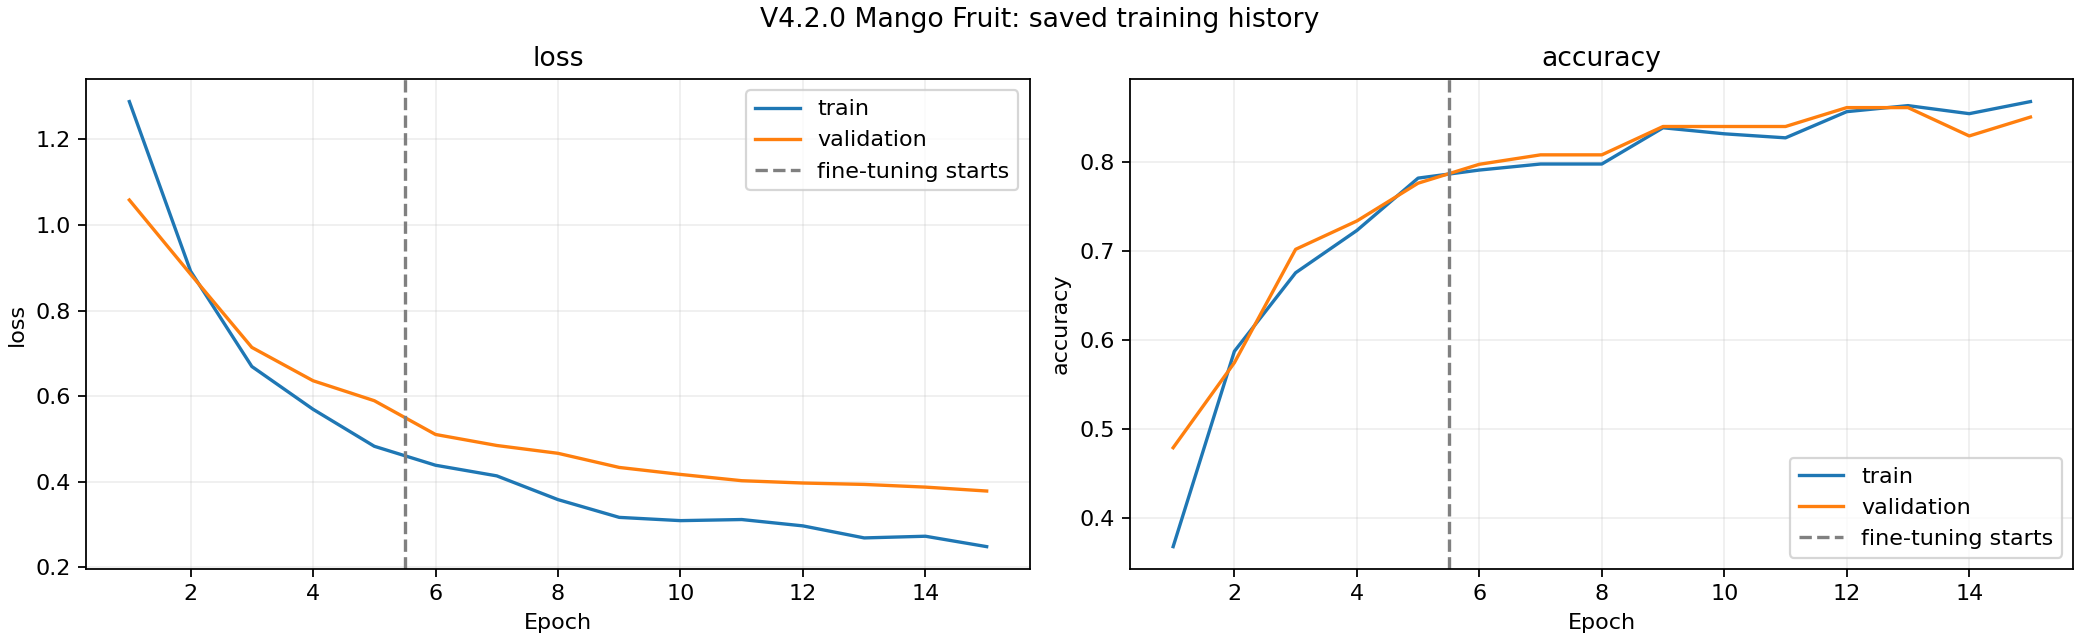

augmentation_preview.png


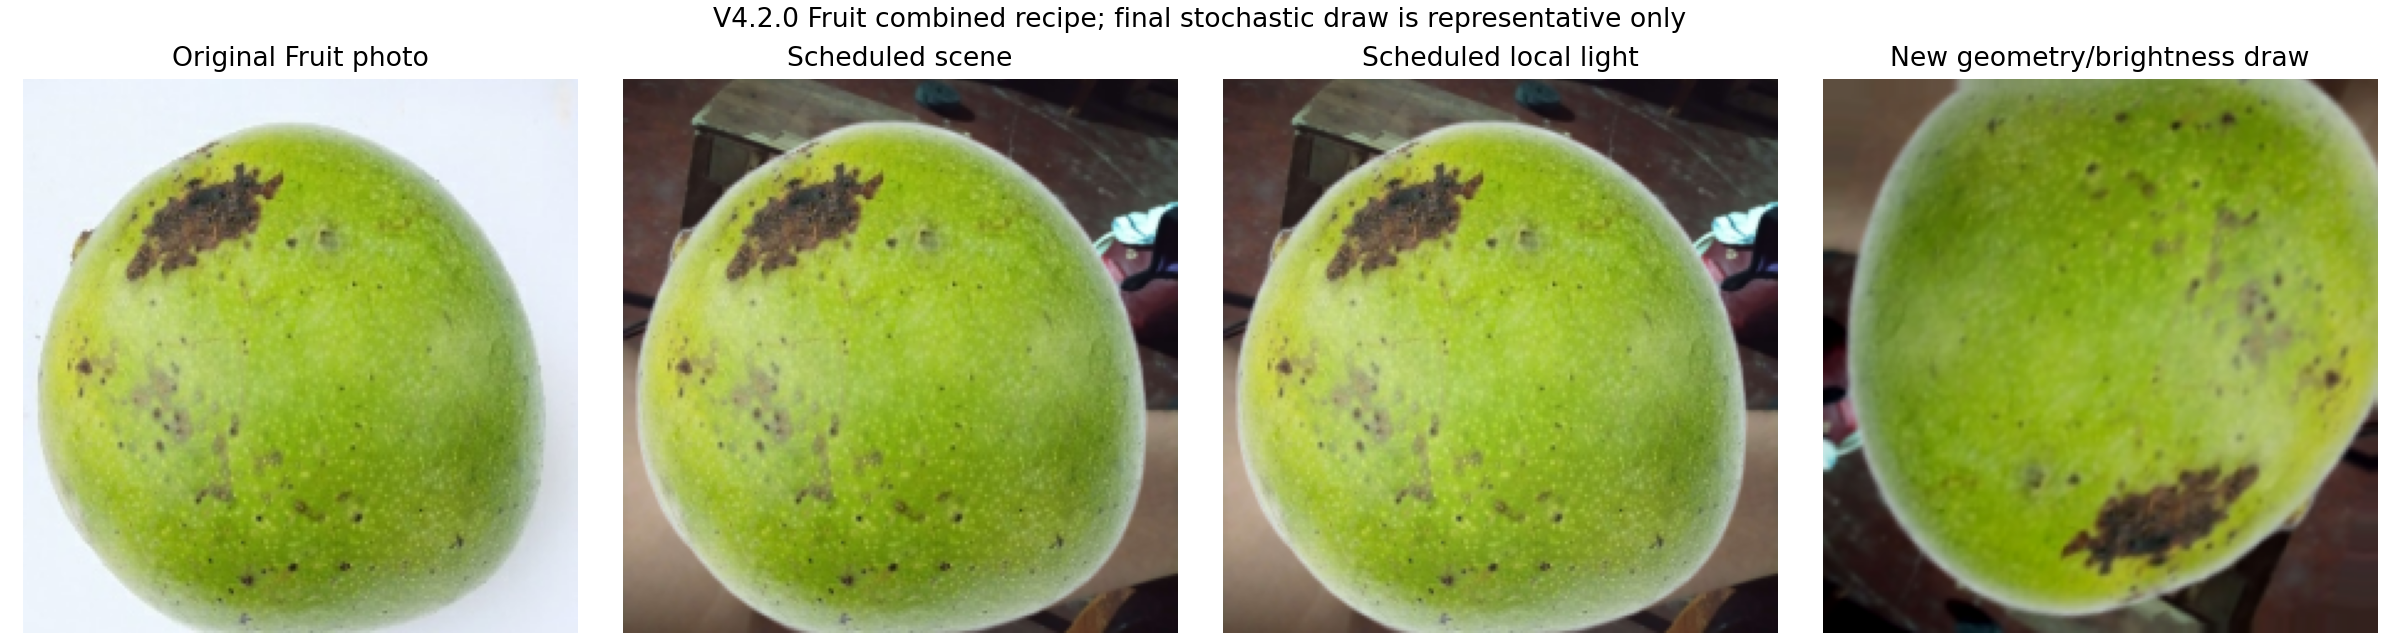

confusion_matrix.png


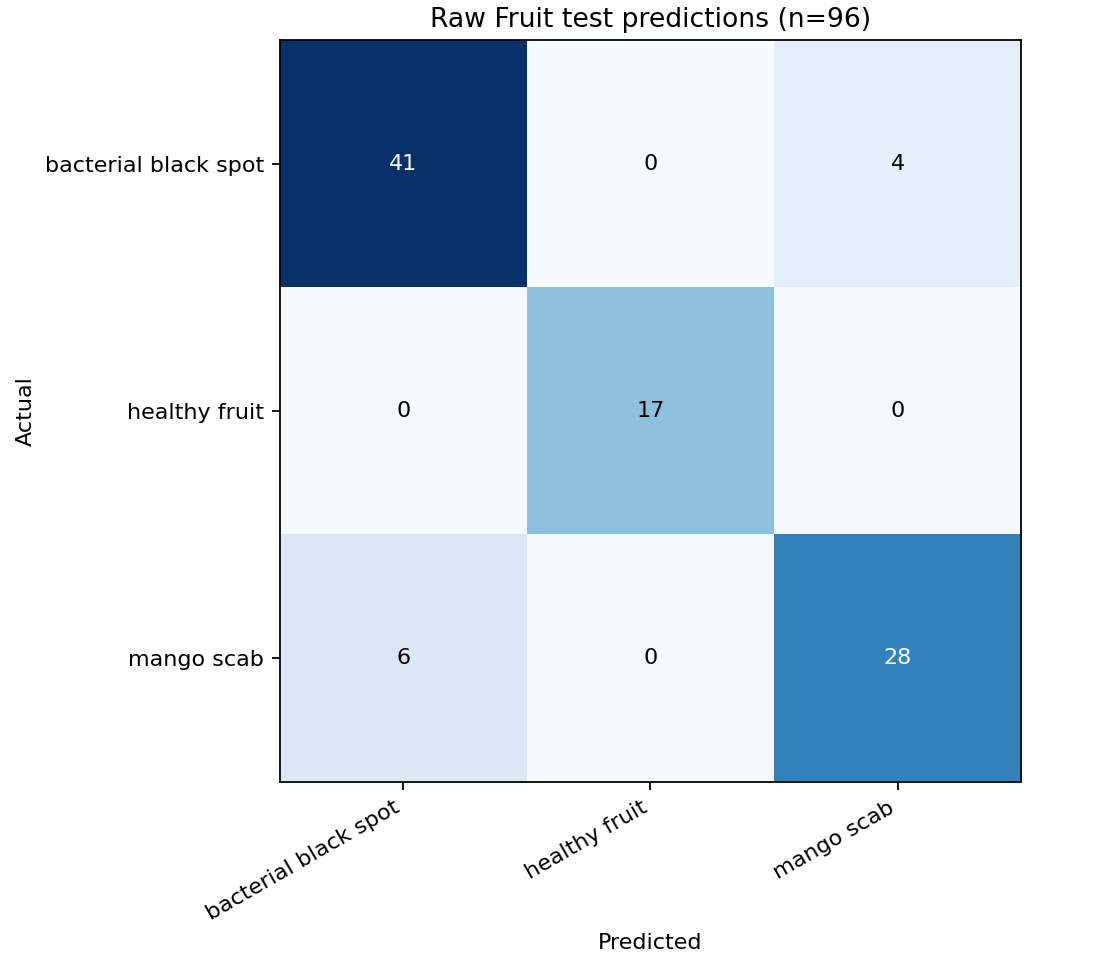

per_class_metrics.png


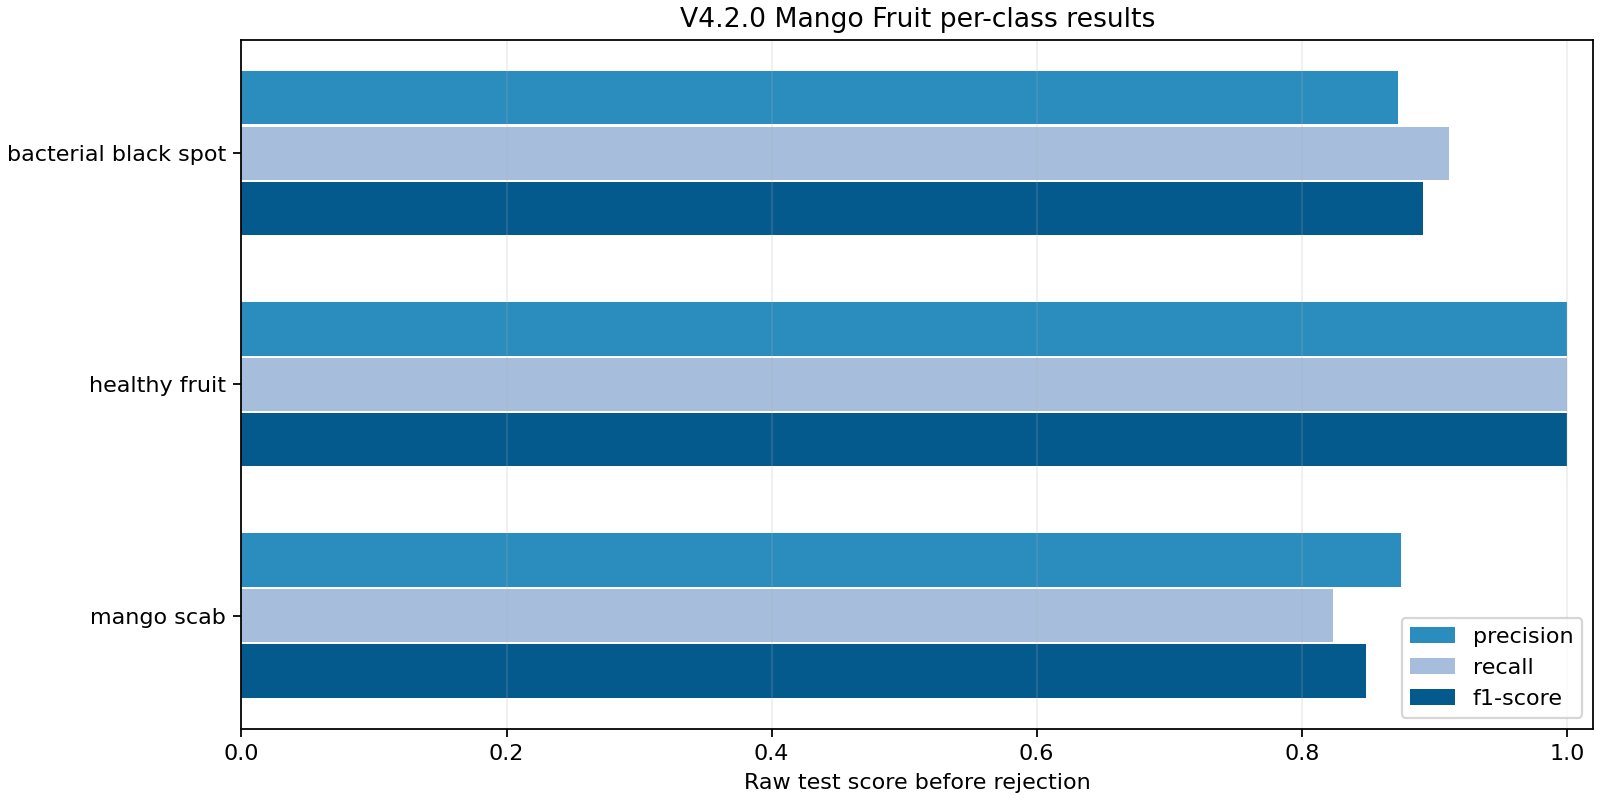

threshold_search.png


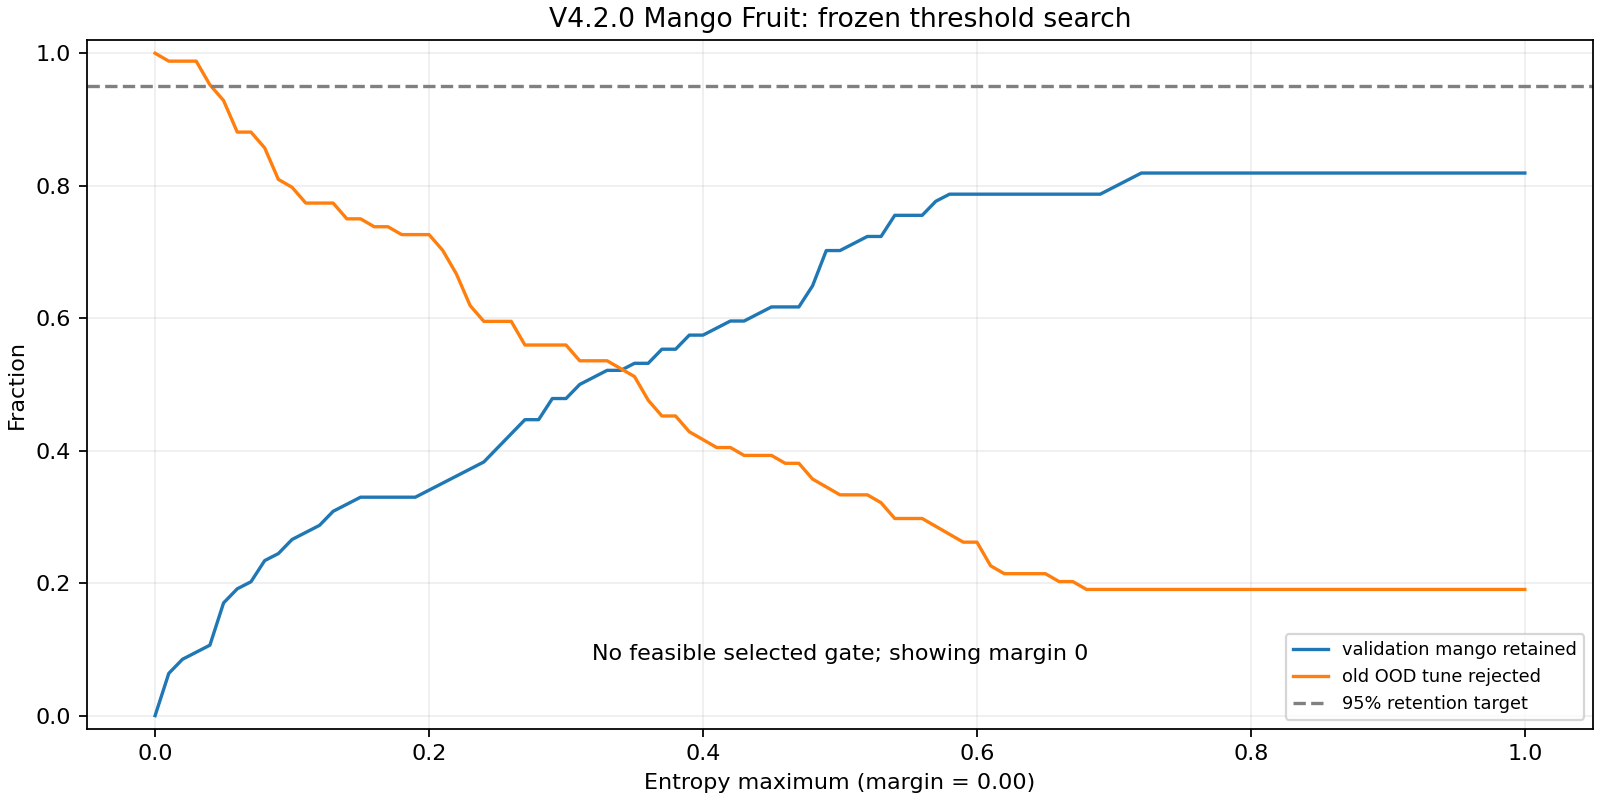

grad_cam.png


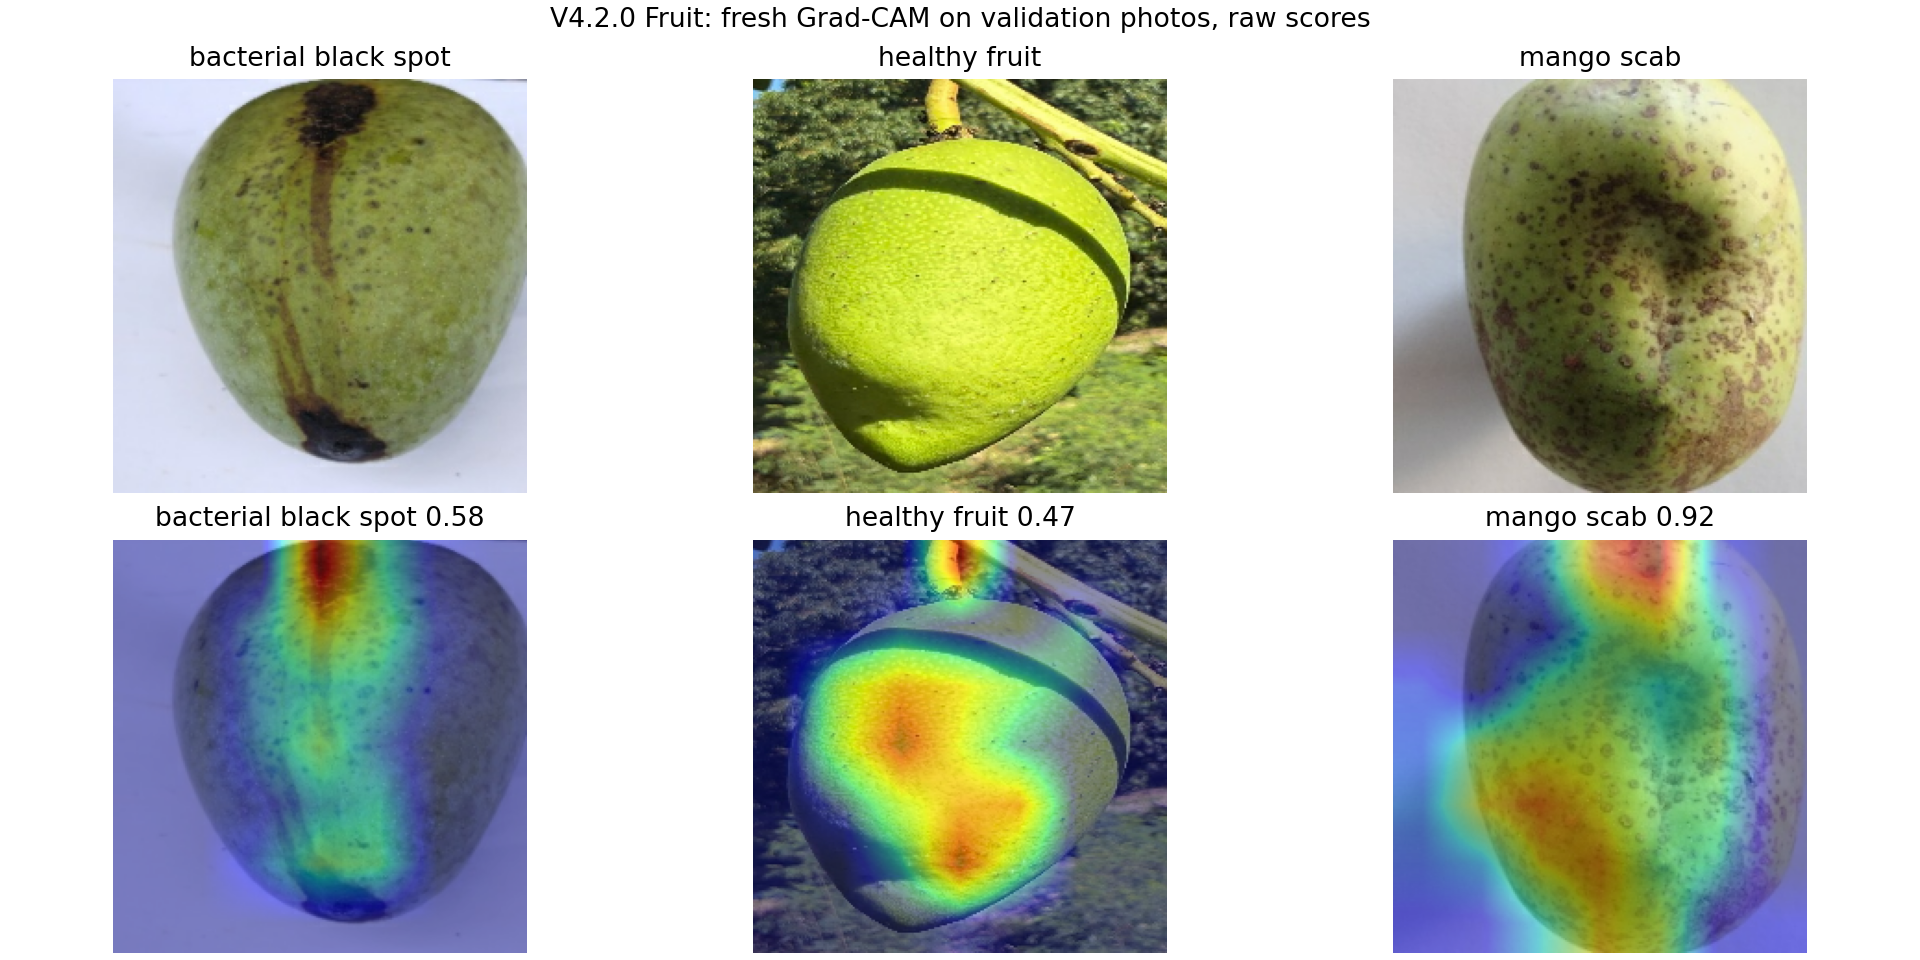

Figure provenance: /content/drive/MyDrive/mangoleaf_experiments/v4.2.0/post_training_figures/mangofruit/v4-2-0-mangofruit-figures-20260929T055036Z/figure_provenance.json


In [6]:
from IPython.display import display
for name in ('training_curves.png', 'augmentation_preview.png', 'confusion_matrix.png',
             'per_class_metrics.png', 'threshold_search.png', 'grad_cam.png'):
    path = OUTPUT_DIR/name
    if not path.is_file():
        raise FileNotFoundError(path)
    print(name)
    display(Image.open(path))
print('Figure provenance:', OUTPUT_DIR/'figure_provenance.json')
